# Extra - Segmentação Semântica de Fácies Sísmicas

Neste notebook, iremos revisar o *pipeline* completo de Visão Computacional estudado ao longo da semana. Aplicaremos ele para a tarefa de segmentação semântica de fácies sísmicas utilizando os dados públicos **Netherlands F3 block**.

> Este notebook foi inspirado pelo artigo [*A Machine Laerning Benchmark for Facies Classification*](https://arxiv.org/abs/1901.07659) de *Alaudah et al.*

In [1]:
import os
import PIL
import random
import collections
import numpy as np
import matplotlib.pyplot as plt
import torchvision.transforms.v2 as T

import torch
import torch.nn as nn
import torch.optim as optim

from tqdm.notebook import tqdm
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset, Sampler

## Contextualização dos dados


O dataset **Netherlands F3 Block** é um conjunto de dados sísmicos 3D de alta qualidade e bem anotado, tornando-se um recurso valioso para pesquisadores que trabalham com interpretação sísmica e aprendizado de máquina, tendo as seguintes informações relevantes:

1. **``Localização:``** Mar do Norte, Holanda.
   
2. **``Data de aquisição:``** 1987, podendo ser um fator limitante de qualidade devido à tecnologia de levantamento sísmico mais antiga.
   
3. **``Tipo de levantamento:``** Levantamento sísmico convencional, podendo ter uma resolução inferior em comparação com levantamentos mais recentes.

4. **``Área de cobertura:``** Aproximadamente $384\text{km}^2$.

5. **``Resolução:``** Considerada alta para a época da aquisição.

6. **``Anotação:``** Interpretações manuais de horizontes e falhas.

7. **``Disponibilidade:``** Base pública (verifique a fonte original para detalhes de acesso).

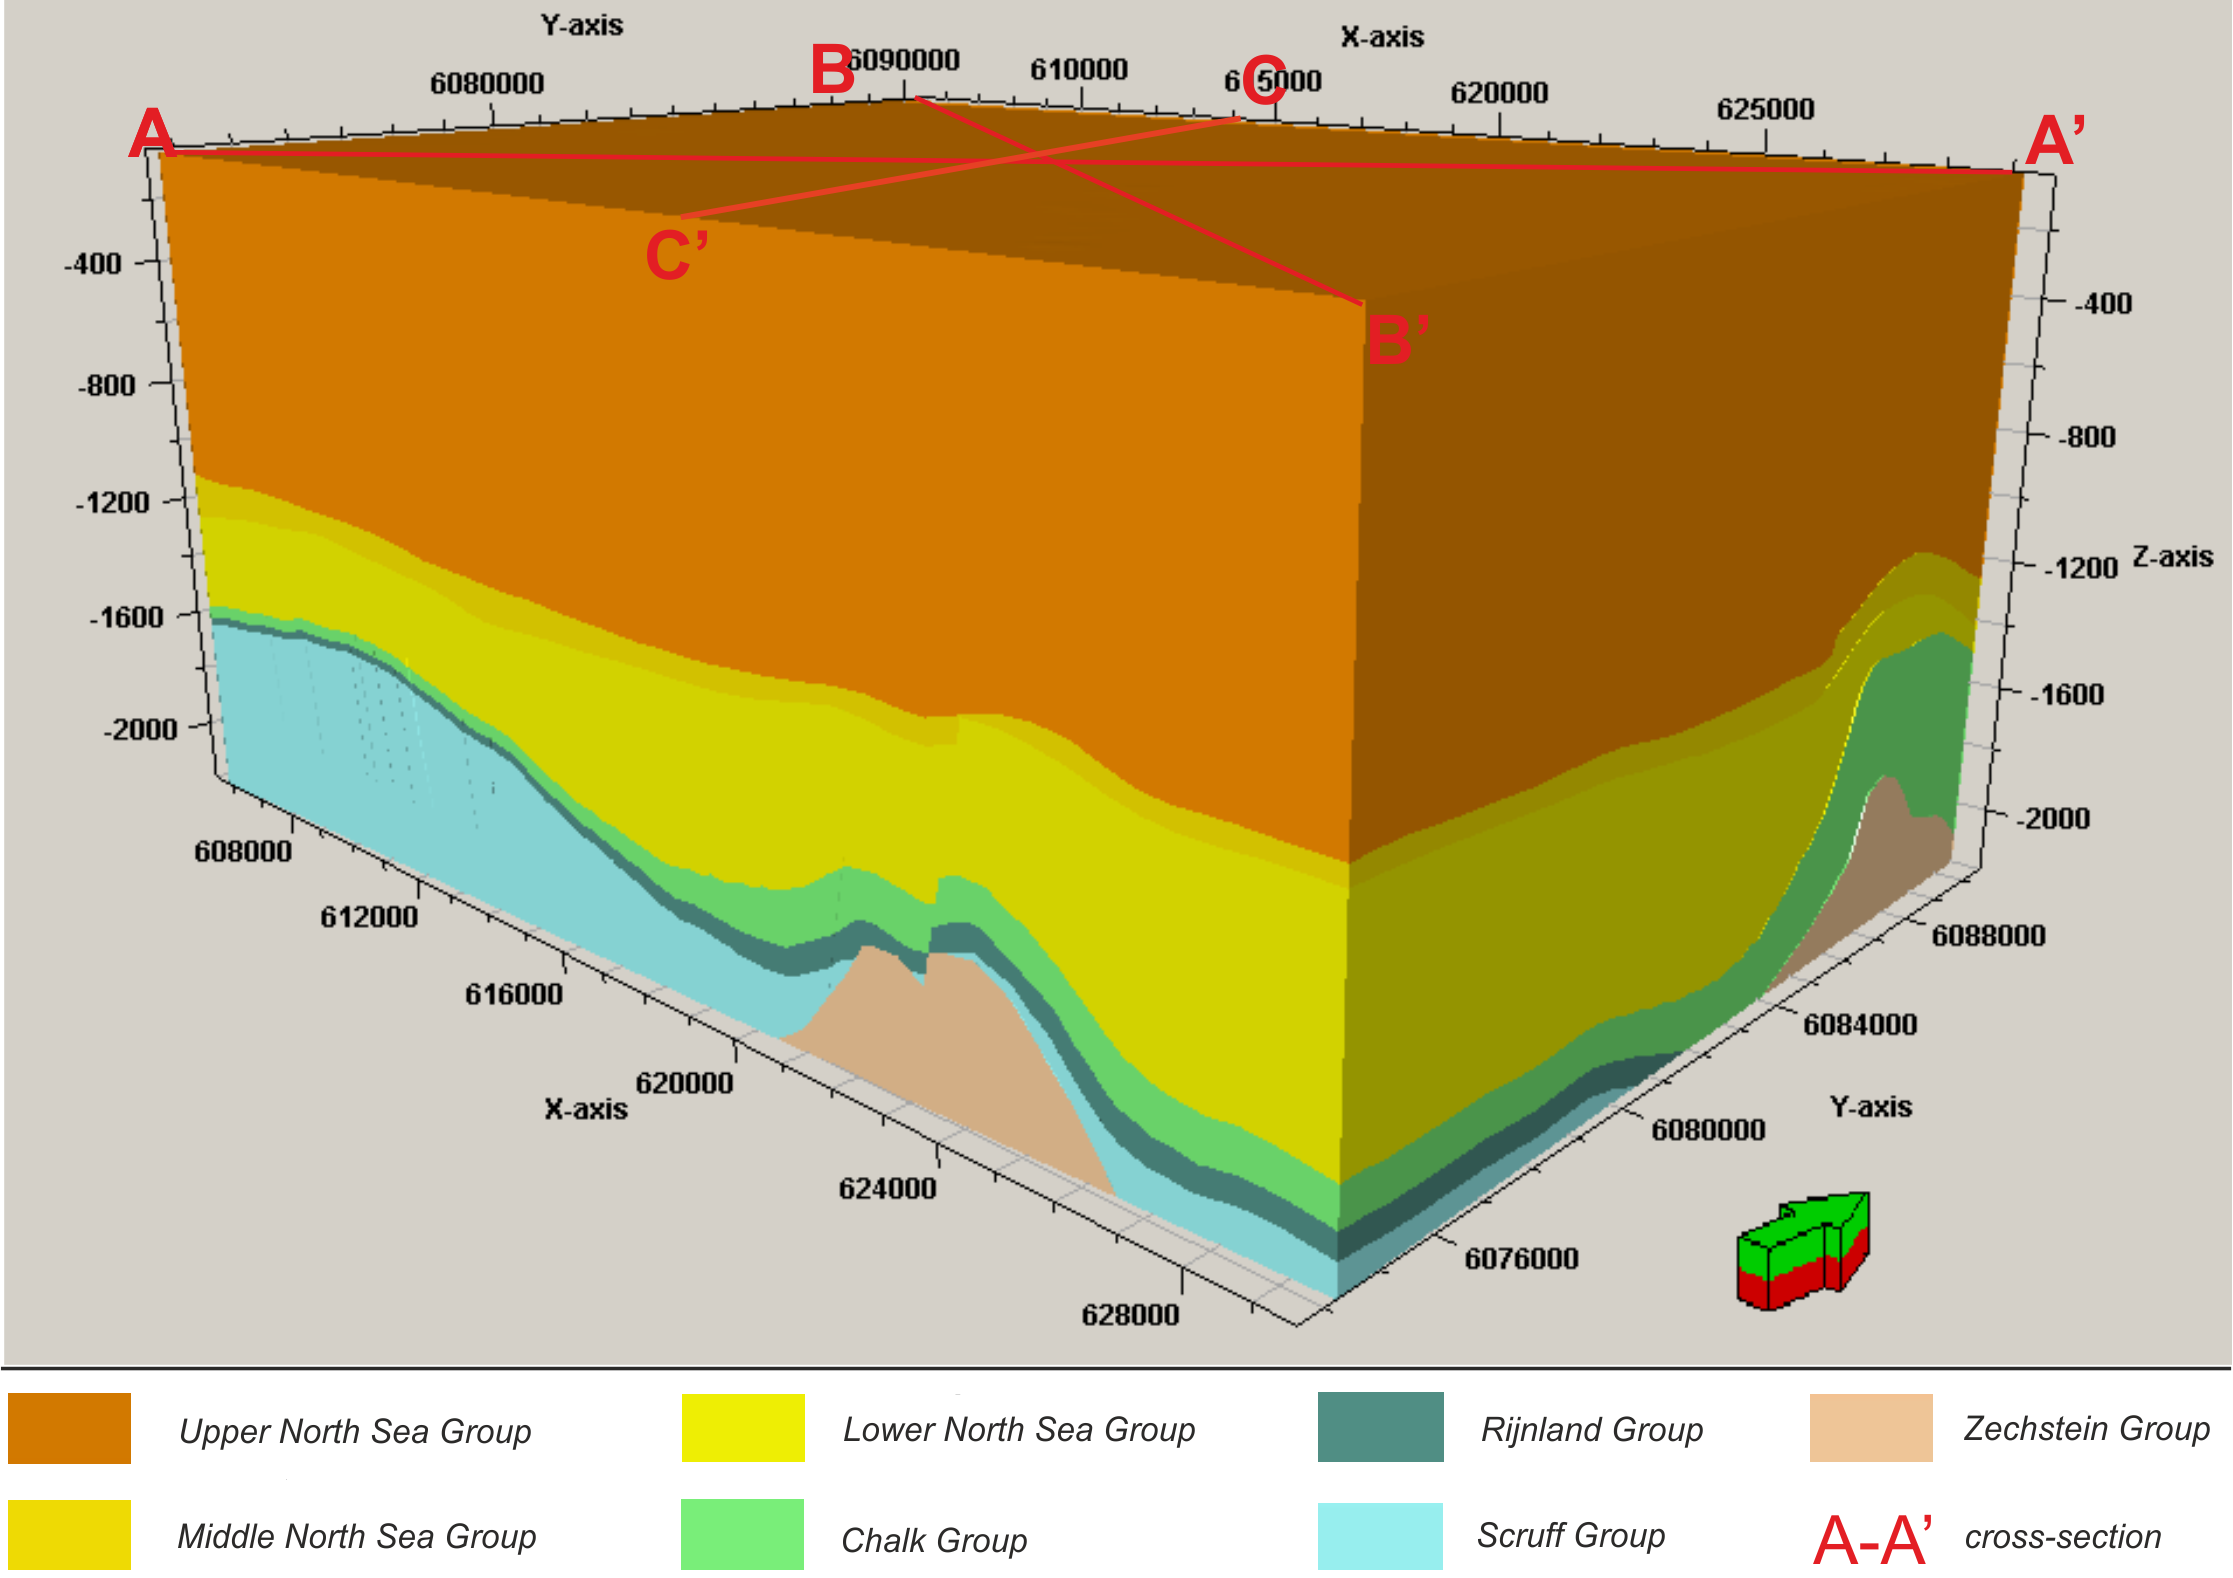


## Entendimento dos dados
### Entrada e saída do modelo

Uma das perguntas mais fundamentais que devemos fazer quando estamos trabalhando com um problema novo é ___"qual será a entrada e a saída do meu modelo?"___, inclusive até mesmo antes de definir qual arquitetura iremos trabalhar!

No caso da tarefa que queremos resolver neste notebook, teremos o seguinte par de entrada e saída:
- **`Entrada:`** queremos trabalhar com **imagens sísmicas 2D** do volume extraído e anotado por *Alaudah et al.* Devido a tarefa que queremos resolver (segmentação de fácies), podemos passar como entrada para o nosso modelo tanto *inlines* quanto *crosslines* do nosso volume sísmico, atentando claro às dimensionalidades de cada dado.

- **`Saída:`** queremos que o nosso modelo nos dê como saída a **segmentação de fácies das imagens sísmicas**. No caso do Netherlands F3 Block, assim como discutido no artigo, teremos 6 classes para prever, sendo elas: *Upper North Sea group*, *Middle North Sea group*, *Lower North Sea group*, *Chalk group*, *Rijnland group*, *Scruff group* e *Zechstein group*.

Para termos um exemplo um pouco mais visual, iremos visualizar o que seria uma imagem de entrada e uma de saída no caso do F3.

Os dados de treino e teste estão organizados em arquivos `.npy`, que são fáceis de carregar utilizando a função `np.load` do módulo NumPy.

In [3]:
dataset_path = '/pgeoprj2/ciag2024/dados/f3/'

labels = np.load(os.path.join(dataset_path, 'train/train_labels.npy'))
inputs = np.load(os.path.join(dataset_path, 'train/train_seismic.npy'))

inputs.shape, labels.shape

((401, 701, 255), (401, 701, 255))

Como podemos ver acima, trabalharemos com um volume sísmico de dimensões $401 \times 701 \times 255$.

Iremos extrair o primeiro *inline* dos dados de entrada e saída e observá-los.

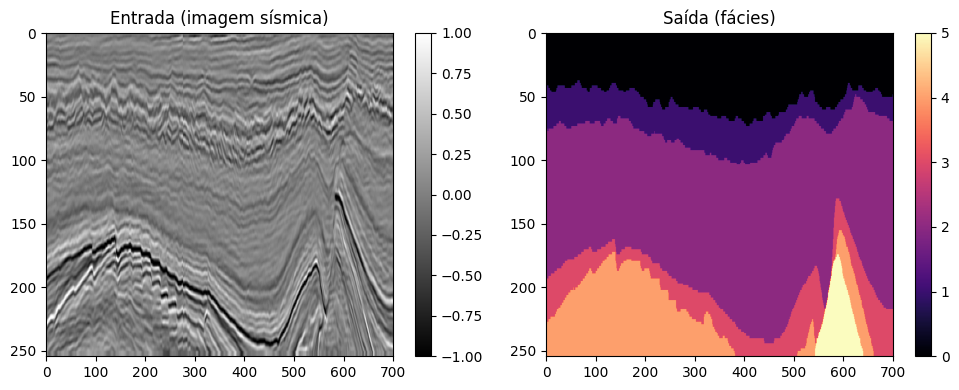

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].set_title('Entrada (imagem sísmica)')
img0 = axs[0].imshow(inputs[0].T, cmap='gray', aspect='auto')

axs[1].set_title('Saída (fácies)')
img1 = axs[1].imshow(labels[0].T, cmap='magma', aspect='auto')

fig.colorbar(img0, ax=axs[0])
fig.colorbar(img1, ax=axs[1])
fig.tight_layout()

Analogamente, podemos extrair o primeiro *crossline*.

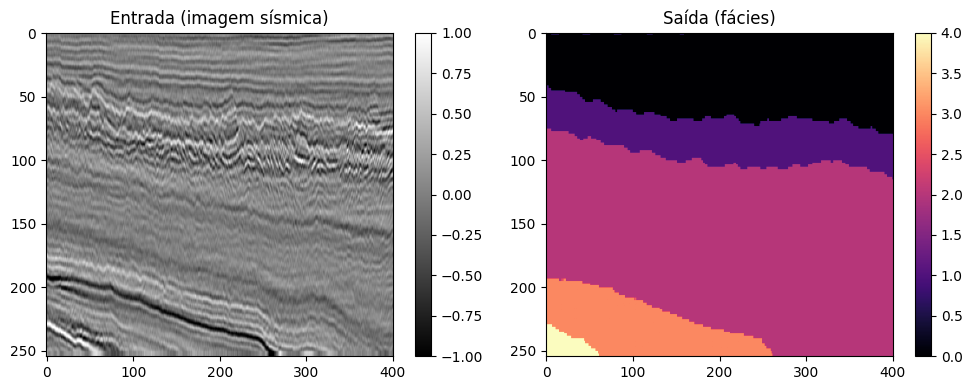

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].set_title('Entrada (imagem sísmica)')
img0 = axs[0].imshow(inputs[:, 0].T, cmap='gray', aspect='auto')

axs[1].set_title('Saída (fácies)')
img1 = axs[1].imshow(labels[:, 0].T, cmap='magma', aspect='auto')

fig.colorbar(img0, ax=axs[0])
fig.colorbar(img1, ax=axs[1])
fig.tight_layout()

E, se for de interesse, até mesmo um *timeslice*.

Porém, nesse notebook, iremos fazer apenas previsões 2D ao longo dos *inlines* e/ou *crosslines*.

> **Nota:** Nesse caso, a sintaxe `[..., 0]` é equivalente a fazermos `[:, :, 0]`.

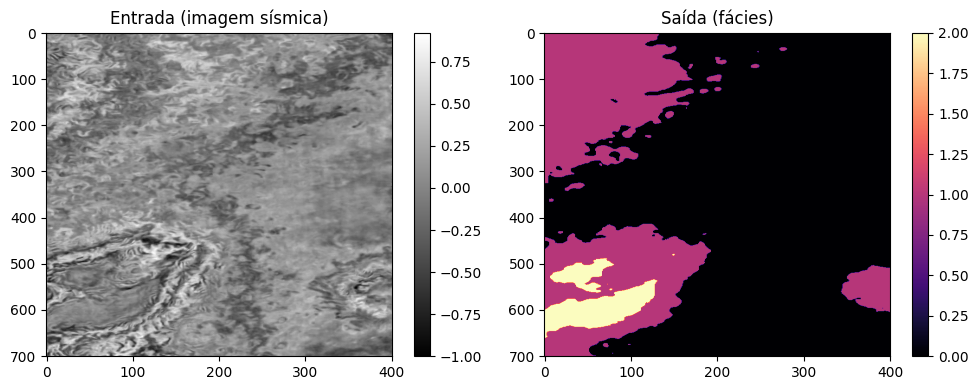

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].set_title('Entrada (imagem sísmica)')
img0 = axs[0].imshow(inputs[..., 64].T, cmap='gray', aspect='auto')

axs[1].set_title('Saída (fácies)')
img1 = axs[1].imshow(labels[..., 64].T, cmap='magma', aspect='auto')

fig.colorbar(img0, ax=axs[0])
fig.colorbar(img1, ax=axs[1])
fig.tight_layout()

## Pré-processamentos e preparação do dataset

Antes de trabalhar efetivamente no nosso modelo neural, devemos refletir sobre quais são os pré-processamentos necessários para garantir uma melhor convergência do nosso modelo. Alguns pré-processamentos envolvem, por exemplo:

- **`Normalização:`** tipicamente podemos trabalhar com dados que foram adquiridos de formas diferentes, e assim, podendo estar em escalas diferentes. Como por exemplo, imagens nos quais os pixels estão no intervalo `[-1, 1]`, `[0, 1]` ou até mesmo `[0, 255]`. Sendo assim, técnicas de normalização como MinMax ou padronização como Z-Score, são fundamentais para garantir uma melhor convergência do treinamento do nosso modelo.

- **`Correções de desbalanceamento:`** em diversos problemas, iremos ter um alto desbalanceamento de classes nos nossos dados, enviesando o modelo a prever a classe com maior frequência no pior dos casos. Para isso, podemos calcular pesos para reponderar as classes ou usar técnicas mais severas como *undersampling* e remoção de *outliers*, que sempre devem ser feitas com cuidado. O *oversampling* também é uma opção, feita atráves de *data augmentation*.

- **`Garantir rotulação consistente:`** no caso do F3, temos uma anotação de qualidade. Porém, em dados que são tipicamente obtidos através da junção de vários outros conjuntos de dados, a padronização e consistência da anotação é prioridade máxima. Afinal, sem um rótulo bem feito, é bem mais complicado de um modelo de aprendizagem supervisionada ter uma alta performance (*garbage in, garbage out*).

### Desbalanceamento de classes

No caso dos dados do F3, percebemos claramente através de algumas inspeções dos rótulos que temos um **desbalanceio de classes**, onde as classes do grupo *North Sea group* são em maior quantidade. O artigo de *Alaudah et al.* discute e demonstra esse desbalanceio brevemente.

Podemos utilizar diversas heurísticas para associar um peso para cada classe, efetivamente guiando a otimização do modelo a ser penalizado mais na predição errada de classes minoritárias. Uma heurística simples que podemos pensar é em associar o peso da classe $i$ como sendo o inverso da proporção média da classe $i$.

In [19]:
class_weights = np.ones(6, dtype=np.float32)
class_weights  # por padrão, os pesos das classes são 1

array([1., 1., 1., 1., 1., 1.], dtype=float32)

In [20]:
for i in range(6):
    mean_class_count = np.sum(labels == i, axis=(0, 1)).mean()
    class_proportion = mean_class_count / (labels.shape[0] * labels.shape[1])
    class_weights[i] = 1 / class_proportion

class_weights  # agora temos pesos menores para classes majoritárias e vice-versa

array([ 3.5595057,  8.413564 ,  2.0579515, 15.056521 , 30.500502 ,
       66.29741  ], dtype=float32)

> **Nota:** Aqui estamos computando o desbalanceio de classes apenas nos dados de treino! Lembre-se de tudo relacionado ao pré-processamento, como por exemplo o cálculo de $\mu$ e $\sigma$ para o cálculo do Z-Score, deve ser feito sobre os dados de treino!

### Normalização dos dados

Um segundo pré-processamento que podemos realizar é um **Z-Score Normalization** das entradas da nossa rede. Para isso, iremos calcular a média e desvio padrão do volume sísmico e aplicar a fórmula do Z-Score sobre o volume original.

$$
x_\text{z-score} = \dfrac{x - \mu}{\sigma}
$$

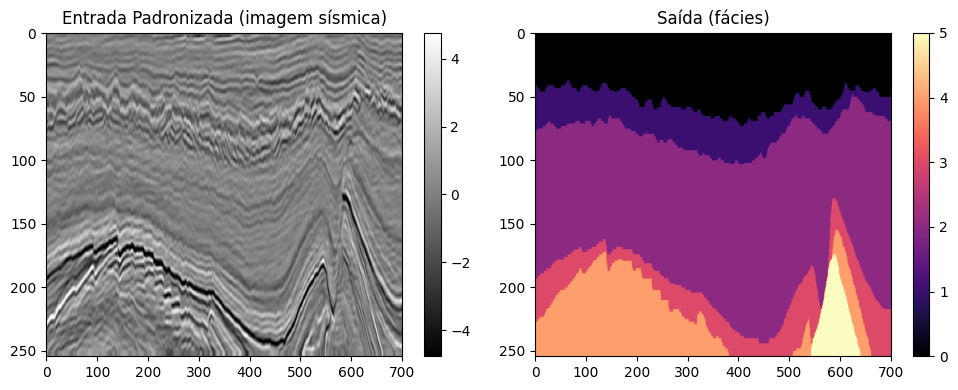

In [21]:
def zscore(x):
    return (x - x.mean()) / x.std()

z_inputs = zscore(inputs)

fig, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].set_title('Entrada Padronizada (imagem sísmica)')
img0 = axs[0].imshow(z_inputs[0].T, cmap='gray', aspect='auto')

axs[1].set_title('Saída (fácies)')
img1 = axs[1].imshow(labels[0].T, cmap='magma', aspect='auto')

fig.colorbar(img0, ax=axs[0])
fig.colorbar(img1, ax=axs[1])
fig.tight_layout()

Uma segunda opção simples de normalização é o *min-max normalization*, onde aplicamos a seguinte fórmula:

$$
x_\text{minmax} = \dfrac{x - x_\text{min}}{x_\text{max} - x_\text{min}}
$$

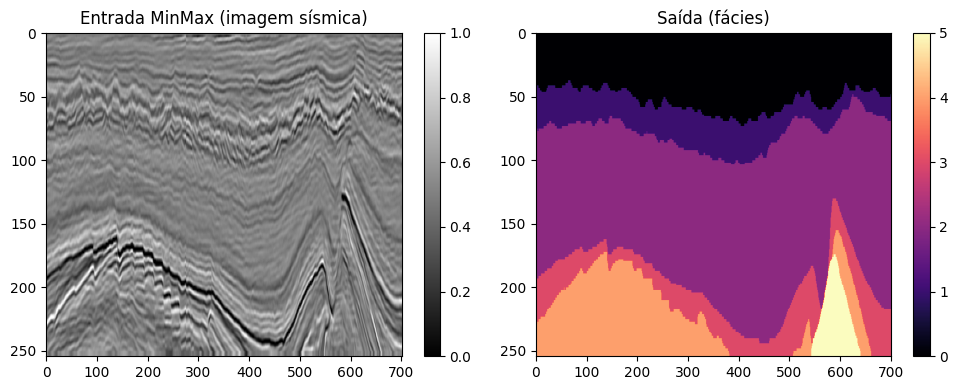

In [22]:
def minmax(x):
    return (x - x.min()) / (x.max() - x.min())

minmax_inputs = minmax(inputs)

fig, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].set_title('Entrada MinMax (imagem sísmica)')
img0 = axs[0].imshow(minmax_inputs[0].T, cmap='gray', aspect='auto')

axs[1].set_title('Saída (fácies)')
img1 = axs[1].imshow(labels[0].T, cmap='magma', aspect='auto')

fig.colorbar(img0, ax=axs[0])
fig.colorbar(img1, ax=axs[1])
fig.tight_layout()

### Data Augmentation

*Data augmentation* é uma das principais técnicas utilizadas em Machine Learning, e Deep Learning, para garantir uma melhor generalização e tratamento de desbalanceamento de classes.

Podemos aplicar facilmente algumas transformações através do módulo [`torchvision`](https://pytorch.org/vision/stable/transforms.html). Porém, devemos tomar cuidado já que nem todas as transformações são válidas para o nosso contexto sísmico!

> **Nota:** Podemos usar o módulo `v2.Compose` (ou com os nossos imports: `T.Compose`) para compor transformações sobre o nosso dado.

In [27]:
random_vertical_flip = T.RandomVerticalFlip(p=0.5)

# Antes de usar o augmentation, precisamos converter o numpy array para um tensor torch.
# Estaremos também convertendo o dado para float32
inputs_tensor = torch.from_numpy(inputs).float()

flipped_inputs = random_vertical_flip(inputs_tensor)
flipped_inputs.shape, flipped_inputs.dtype

(torch.Size([401, 701, 255]), torch.float32)

In [28]:
# Agora usando a interface Compose
transforms = T.Compose([
    T.ToImage(),  # antigamente era o ToTensor, porém ele será depricated
    T.ToDtype(torch.float32),
    T.Lambda(lambda t: t.permute(1, 2, 0)),  # numpy: (W, H, C), torch: (C, W, H)

    # Espelhando a imagem verticalmente
    T.RandomVerticalFlip(p=0.5)
])

transformed_inputs = transforms(inputs)
transformed_inputs.shape, transformed_inputs.dtype

(torch.Size([401, 701, 255]), torch.float32)

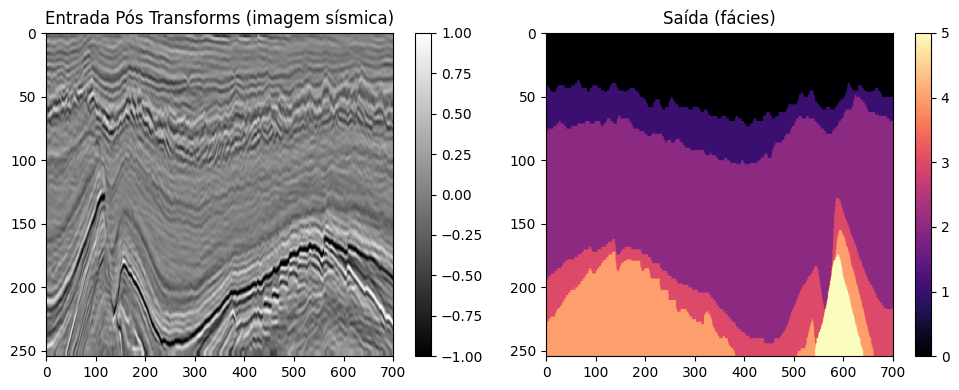

In [29]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].set_title('Entrada Pós Transforms (imagem sísmica)')
img0 = axs[0].imshow(transformed_inputs[0].T, cmap='gray', aspect='auto')

axs[1].set_title('Saída (fácies)')
img1 = axs[1].imshow(labels[0].T, cmap='magma', aspect='auto')

fig.colorbar(img0, ax=axs[0])
fig.colorbar(img1, ax=axs[1])
fig.tight_layout()

> **Nota:** Como possivelmente observado acima, o `RandomVerticalFlip` deve ser usado com sabedoria. Muito provavelmente observaremos uma inconsistência entre o dado de entrada e de saída, dado que não aplicamos a exata mesma transformação em ambos. Caso não observe nenhuma inconsistência, significa que o `RandomVerticalFlip` não foi executado dado o seu comportamento estocástico.

### Divisão dos dados

Tipicamente em um projeto de Machine Learning e Deep Learning nos deparamos com a seguinte divisão dos dados: treino, validação e teste, onde cada conjunto possui um propósito específico.

- **`Treino:`** como o próprio nome já diz, será o conjunto dos dados que iremos efetivamente treinar o nosso modelo.

- **`Validação:`** tipicamente sendo um subconjunto dos dados de treino, esse conjunto de dados serve o propósito de nos auxiliar durante a escolha da melhor arquitetura e hiperparâmetros (como o tamanho do *batch*) durante os diversos experimentos.

- **`Teste:`** utilizado para "simular" um cenário real, onde iremos avaliar a performance dos modelos em dados que não utilizamos nem durante o treinamento e validação.


> **Nota:** É usual a divisão entre esses três conjuntos em proporções de `6:2:2` ou `8:1:1`. Porém, também podemos encontrar casos onde queremos uma divisão `7:2:1`.

Como o F3 não possui formalmente um conjunto de validação, iremos extrair *inlines* e *crosslines* do dado de treino para cumprir este papel. Porém, não podemos extrair simplesmente fatias do nosso dado de treino aleatoriamente dado o caráter espacial dele. Muito provavelmente, teremos vazamento de informação entre seções adjacentes.

Sendo assim, iremos realizar uma divisão 80% - 20% do dado, deixando os últimos 20% *inlines* do cubo para compor o conjunto de validação.

In [30]:
num_inlines = inputs.shape[0]
print('Número de inlines:', num_inlines)

train_inlines = list(range(0, int(0.8 * num_inlines)))
valid_inlines = list(range(int(0.8 * num_inlines), num_inlines))

assert train_inlines[-1] != valid_inlines[0]

print('Inlines para treino:', len(train_inlines))
print('Inlines para validação:', len(valid_inlines))

Número de inlines: 401
Inlines para treino: 320
Inlines para validação: 81


In [31]:
train_inputs = inputs[train_inlines]
train_labels = labels[train_inlines]

valid_inputs = inputs[valid_inlines]
valid_labels = labels[valid_inlines]

print('Tamanho dos dados de treino:', train_inputs.shape)
print('Tamanho dos dados de validação:', valid_inputs.shape)

Tamanho dos dados de treino: (320, 701, 255)
Tamanho dos dados de validação: (81, 701, 255)


### Criação do objeto Dataset

In [130]:
class F3BlockDataset(Dataset):
    """
    Data loader for the section-based strategy for the NL dataset.

    Loads seismic and label data from the specified dataset split (train, valid, test1, or test2),
    optionally applies data augmentation, and transforms data into PyTorch tensors for training.
    Provides methods for decoding segmentation masks, accessing class information, and generating K-fold splits.
    """

    def __init__(self, input_subvolume: np.ndarray, label_subvolume: np.ndarray, input_transforms=None, transforms=None):
        """
        Initializes the dataset.

        Arguments
        ---------
            - input_subvolume (np.ndarray): which subvolume to load from the F3 block.
            - label_subvolume (np.ndarray): the label subvolume associated with the input subvolume.
            - input_transforms (np.ndarray): transformations used to do transformations on input.
            - transforms (v2.Compose = None): transformations used to do data augmentation on input and label.
        """

        assert input_subvolume.shape == label_subvolume.shape

        self.n_classes = 6
        self.input_subvolume = input_subvolume
        self.label_subvolume = label_subvolume
        
        self.transforms = transforms
        self.input_transforms = input_transforms

        num_inlines, num_crosslines, depth = input_subvolume.shape
        il_list, xl_list = list(range(num_inlines)), list(range(num_crosslines))

        il_list = ['i_' + str(inline) for inline in il_list]
        xl_list = ['x_' + str(crossline) for crossline in xl_list]
        self.sections = il_list + xl_list

    def __len__(self):
        """ Returns the total number of sections in the subvolume """
        return len(self.sections)

    def __getitem__(self, idx):
        """
        Retrieves a single data sample (seismic image and label) at the specified index.

        Arguments
        ---------
            - idx (int): Index of the sample to retrieve.

        Return
        ------
            - tuple: A tuple containing the seismic image (torch.Tensor) and label mask (torch.Tensor).
        """

        section_name = self.sections[idx]
        direction, number = section_name.split('_')
        slice_number = int(number)
        
        if direction == 'i':
            label = self.label_subvolume[slice_number, :, :]
            seismic = self.input_subvolume[slice_number, :, :]

        elif direction == 'x':
            label = self.label_subvolume[:, slice_number, :]
            seismic = self.input_subvolume[:, slice_number, :]

        else:
            raise ValueError(f'Direction {direction} not found. Must be either i (inlines) or x (crosslines)')

        # Giving the volume orientation we must do a transposition
        label = label.T
        seismic = seismic.T
        
        # Converting input and label to torch tensor and casting dtypes
        label = torch.from_numpy(label).long()
        seismic = torch.from_numpy(seismic).float()

        # Adding channel dimension for transforms to work
        label = label.unsqueeze(0)
        seismic = seismic.unsqueeze(0)

        if self.input_transforms is not None:
            seismic = self.input_transforms(seismic)

        if self.transforms is not None:
            seismic, label = self.transforms((seismic, label))

        # Removing the channel dimension from label to work with losses
        label = label.squeeze()
        
        return seismic, label

    def decode_segmap(self, label_mask, plot=False, save_name=None):
        """
        Decodes a segmentation label mask into a color image.

        Args:
            label_mask (numpy.ndarray): An array of integer class labels.
            plot (bool, optional): Whether to display the decoded image.
            save_name (str, optional): Name to save the decoded image if provided.

        Returns:
            numpy.ndarray: The decoded color image array, or None if plot=True.
        """
        label_colours = self._get_seismic_colors()
        r = label_mask.copy()
        g = label_mask.copy()
        b = label_mask.copy()
        for ll in range(0, self.n_classes):
            r[label_mask == ll] = label_colours[ll, 0]
            g[label_mask == ll] = label_colours[ll, 1]
            b[label_mask == ll] = label_colours[ll, 2]
        rgb = np.zeros((label_mask.shape[0], label_mask.shape[1], 3))
        rgb[:, :, 0] = r / 255.0
        rgb[:, :, 1] = g / 255.0
        rgb[:, :, 2] = b / 255.0
        plt.tight_layout()
        if save_name is not None:
            plt.imshow(rgb)
            plt.savefig(save_name)
        if plot:
            plt.imshow(rgb)
            plt.show()
        else:
            return rgb

    def _get_seismic_colors(self):
        """
        Returns an array of RGB color codes for visualizing seismic data.
        """
        return np.asarray([
            [69, 117, 180],
            [145, 191, 219],
            [224, 243, 248],
            [254, 224, 144],
            [252, 141, 89],
            [215, 48, 39],
        ])

In [131]:
input_transforms = T.Compose([
    T.Normalize((train_inputs.mean(), ), (train_inputs.std(), ))
])

train_dataset = F3BlockDataset(train_inputs, train_labels, input_transforms=input_transforms)
valid_dataset = F3BlockDataset(valid_inputs, valid_labels, input_transforms=input_transforms)

len(train_dataset), len(valid_dataset)

(1021, 782)

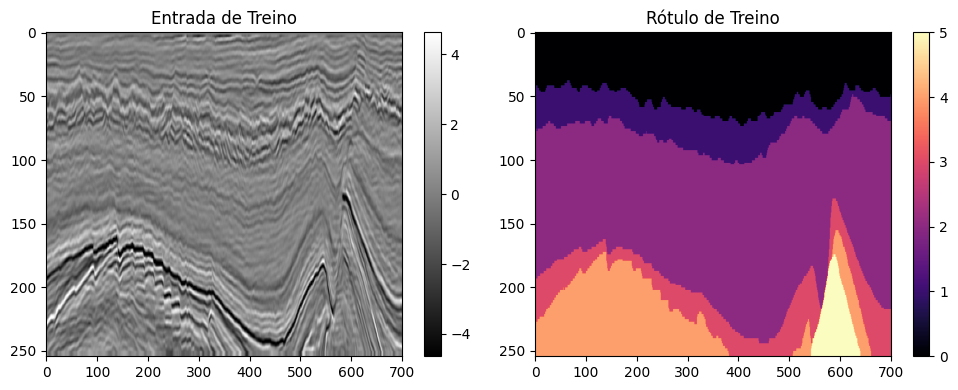

In [132]:
input_sample, label_sample = train_dataset[0]

fig, axs = plt.subplots(1, 2, figsize=(10, 4))

axs[0].set_title('Entrada de Treino')
img0 = axs[0].imshow(input_sample.squeeze(), cmap='gray', aspect='auto')

axs[1].set_title('Rótulo de Treino')
img1 = axs[1].imshow(label_sample, cmap='magma', aspect='auto')

fig.colorbar(img0, ax=axs[0])
fig.colorbar(img1, ax=axs[1])
fig.tight_layout()

In [133]:
class CustomSampler(Sampler):
    def __init__(self, sample_list):
        self.counter = 0
        self.sample_list = sample_list

    def __iter__(self):
        mode = 'i' if (self.counter % 2 == 0) else 'x'
        self.counter += 1
        self.indices = [
            idx for (idx, name) in enumerate(self.sample_list) if mode in name
        ]
        return (self.indices[i] for i in torch.randperm(len(self.indices)))

    def __len__(self):
        mode = 'i' if (self.counter % 2 == 0) else 'x'
        indices = [idx for (idx, name) in enumerate(self.sample_list) if mode in name]
        return len(indices)


# https://pytorch.org/docs/stable/data.html#torch.utils.data.DataLoader
# TODO: crie os dataloaders de treino e validação
train_dataloader = DataLoader(
    train_dataset,
    batch_size=4,
    sampler=CustomSampler(train_dataset.sections),
    num_workers=0,
    shuffle=False,
)

valid_dataloader = DataLoader(
    valid_dataset,
    batch_size=4,
    sampler=CustomSampler(valid_dataset.sections),
    num_workers=0
)

## Definição e treinamento do modelo
### Arquitetura: DeconvNet (Deconvolutional Network)

DeconvNet, também conhecido como rede deconvolucional, é uma arquitetura de rede neural artificial (RNA) inspirada na rede convolucional (CNN). Enquanto as CNNs são usadas para extrair recursos de imagens e realizar tarefas como classificação e reconhecimento de objetos, as DeconvNets são usadas para gerar imagens a partir de representações de alto nível.

As DeconvNets invertem o processo de convolução usado em CNNs. Em vez de usar filtros convolucionais para reduzir a dimensionalidade das entradas, as DeconvNets usam **filtros de deconvolução** para aumentar a dimensionalidade das entradas. Isso significa que elas podem transformar representações compactas de alto nível em imagens com alta resolução espacial.

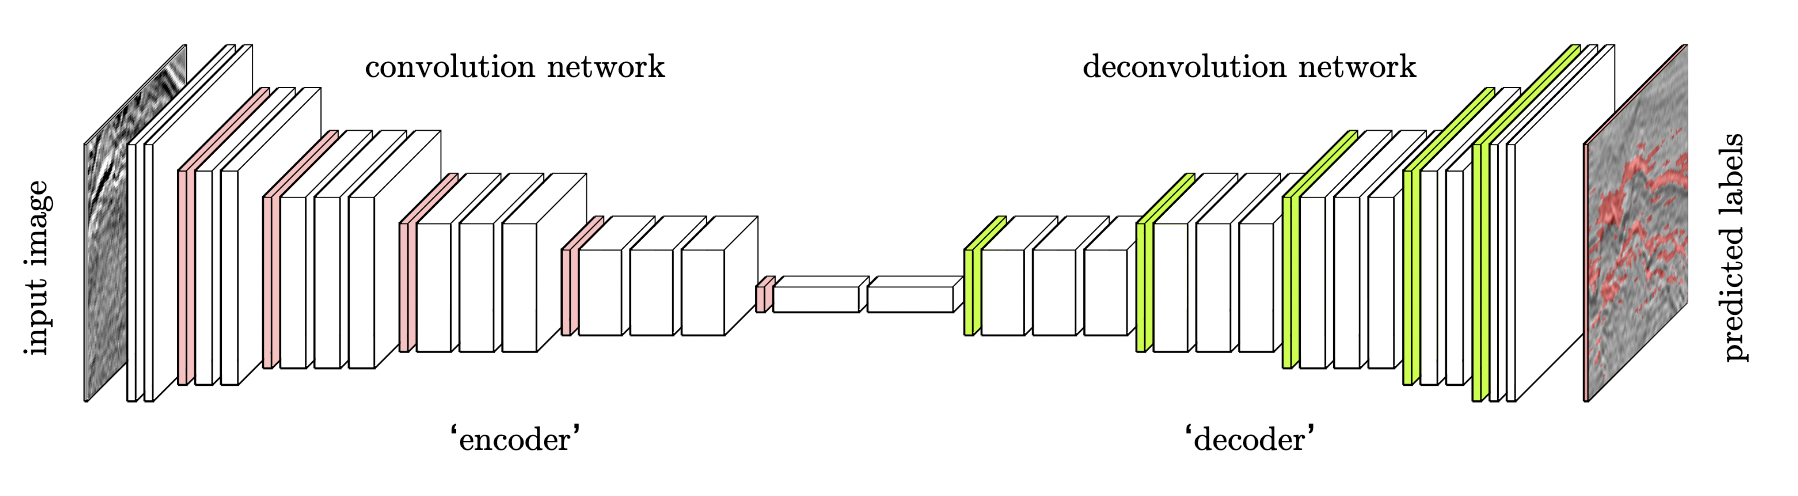

In [134]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, padding=1):
        super(ConvBlock, self).__init__()
        self.conv = nn.Conv2d(
            in_channels, out_channels, kernel_size=kernel_size, padding=padding
        )
        self.bn = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.relu(self.bn(self.conv(x)))


class DeconvBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size=3, padding=1):
        super(DeconvBlock, self).__init__()
        self.deconv = nn.ConvTranspose2d(
            in_channels, out_channels, kernel_size=kernel_size, padding=padding
        )
        self.bn = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU()

    def forward(self, x):
        return self.relu(self.bn(self.deconv(x)))

In [135]:
class DeconvNet(nn.Module):
    """
    DeconvNet model for semantic segmentation, inspired by VGG16 architecture.

    It consists of a contracting path (similar to VGG16) followed by an
    expanding path with unpooling and deconvolution layers.
    """

    def __init__(self, n_channels=1, n_classes=6):
        """
        Initializes the DeconvNet model.

        Args:
            n_channels (int, optional): Number of input channels (default: 1).
            n_classes (int, optional): Number of output classes (default: 6).
        """
        super(DeconvNet, self).__init__()
        self.n_classes = n_classes
        self.pool = nn.MaxPool2d(2, stride=2, return_indices=True, ceil_mode=True)
        self.unpool = nn.MaxUnpool2d(2, stride=2)

        ### Contracting path (similar to VGG16) ###

        self.conv_block1 = nn.Sequential(
            ConvBlock(n_channels, 64),
            ConvBlock(64, 64),
        )

        # 48*48
        self.conv_block2 = nn.Sequential(
            ConvBlock(64, 128),
            ConvBlock(128, 128),
        )

        # 24*24
        self.conv_block3 = nn.Sequential(
            ConvBlock(128, 256),
            ConvBlock(256, 256),
            ConvBlock(256, 256),
        )

        # 12*12
        self.conv_block4 = nn.Sequential(
            ConvBlock(256, 512),
            ConvBlock(512, 512),
            ConvBlock(512, 512),
        )

        # 6*6
        self.conv_block5 = nn.Sequential(
            ConvBlock(512, 512),
            ConvBlock(512, 512),
            ConvBlock(512, 512),
        )

        # 3*3
        self.conv_block6 = nn.Sequential(
            # set the filter size and nor padding to make output into 1*1
            ConvBlock(512, 4096, kernel_size=3, padding=0),
        )

        # 1*1
        self.conv_block7 = nn.Sequential(
            # set the filter size to make output into 1*1
            ConvBlock(4096, 4096, kernel_size=1, padding=0),
        )

        ### Expanding path ###

        self.deconv_block6 = nn.Sequential(
            DeconvBlock(4096, 512, kernel_size=3, padding=0),
        )

        # 6*6
        self.deconv_block5 = nn.Sequential(
            DeconvBlock(512, 512),
            DeconvBlock(512, 512),
            DeconvBlock(512, 512),
        )

        # 12*12
        self.deconv_block4 = nn.Sequential(
            DeconvBlock(512, 512),
            DeconvBlock(512, 512),
            DeconvBlock(512, 256),
        )

        # 24*24
        self.deconv_block3 = nn.Sequential(
            DeconvBlock(256, 256),
            DeconvBlock(256, 256),
            DeconvBlock(256, 128),
        )

        # 48*48
        self.deconv_block2 = nn.Sequential(
            DeconvBlock(128, 128),
            DeconvBlock(128, 64),
        )

        # 96*96
        self.deconv_block1 = nn.Sequential(
            DeconvBlock(64, 64),
            DeconvBlock(64, 64),
        )

        ### Final segmentation layer ###

        self.seg_score = nn.Sequential(
            nn.Conv2d(64, self.n_classes, kernel_size=1),
        )

    def forward(self, x):
        """
        Forward pass of the DeconvNet model.

        Args:
            x (torch.Tensor): Input tensor of shape (N, C, H, W).

        Returns:
            torch.Tensor: Output tensor of shape (N, n_classes, H, W) containing segmentation predictions.
        """
        size0 = x.size() # (1, 96, 96)
        
        # Contracting path
        x, indices1 = self.pool(self.conv_block1(x)) # (1, 96, 96) -> (64, 48, 48)
        size1 = x.size()
        
        x, indices2 = self.pool(self.conv_block2(x)) # (64, 48, 48) -> (128, 24, 24)
        size2 = x.size()
        
        x, indices3 = self.pool(self.conv_block3(x)) # (128, 24, 24) -> (256, 12, 12)
        size3 = x.size()
        
        x, indices4 = self.pool(self.conv_block4(x)) # (256, 12, 12) -> (512, 6, 6)
        size4 = x.size()
        
        x, indices5 = self.pool(self.conv_block5(x)) # (512, 6, 6) -> (512, 3, 3)
        x = self.conv_block6(x) # (512, 3, 3) -> (4096, 1, 1)
        
        # Center block
        x = self.conv_block7(x) # (4096, 1, 1) -> (4096, 1, 1)

        # Expanding path
        x = self.deconv_block6(x) # (4096, 1, 1) -> (512, 3, 3)
        
        x = self.unpool(x, indices5, output_size=size4) # (512, 3, 3) -> (512, 6, 6)
        x = self.deconv_block5(x) # (512, 6, 6) -> (512, 6, 6)
        
        x = self.unpool(x, indices4, output_size=size3) # (512, 6, 6) -> (512, 12, 12)
        x = self.deconv_block4(x) # (512, 12, 12) -> (256, 12, 12)
        
        x = self.unpool(x, indices3, output_size=size2) # (256, 12, 12) -> (256, 24, 24)
        x = self.deconv_block3(x) # (256, 24, 24) -> (128, 24, 24)
        
        x = self.unpool(x, indices2, output_size=size1) # (128, 24, 24) -> (128, 48, 48)
        x = self.deconv_block2(x) # (128, 48, 48) -> (64, 48, 48) 
        
        x = self.unpool(x, indices1, output_size=size0) # (64, 48, 48) -> (64, 96, 96)
        x = self.deconv_block1(x) # (64, 96, 96) -> (64, 96, 96)
        
        # Final segmentation layer
        out = self.seg_score(x) # (64, 96, 96) -> (n_classes, 96, 96)

        return out

A convolução transposta, também conhecida como deconvolução ou upsampling convolucional, é uma operação fundamental em redes neurais convolucionais (CNNs) que permite aumentar a dimensão espacial de um mapa de feições. Em contraste com a convolução padrão, que reduz a dimensão espacial, a convolução transposta gera um mapa de saída com maior largura, altura ou ambas.

A convolução transposta é utilizada em diversas aplicações de aprendizado de máquina, incluindo:

-   Upsampling de imagens: Permite aumentar a resolução espacial de imagens de baixa resolução, como em tarefas de geração de imagens, super-resolução e segmentação semântica.
-   Síntese de imagens: Gera imagens a partir de representações de alto nível, como em tarefas de geração de imagens e tradução de estilo.
-   Visualização de mapas de feições: Permite visualizar mapas de feições gerados por CNNs em alta resolução, facilitando a interpretação dos resultados.

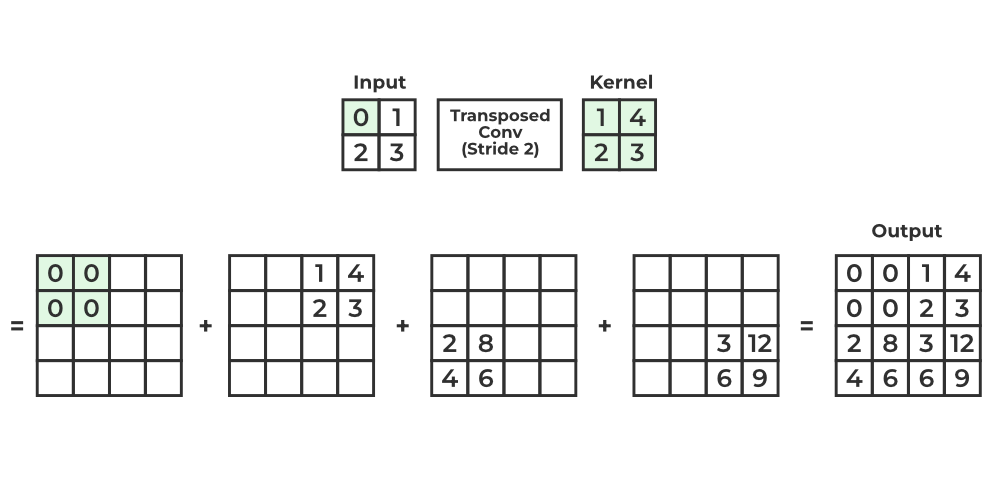


## Exercício 2

-   Agora com sua arquitetura `DeconvNet` definida, crie um objeto especificando corretamente o número de canais de entrada e o número de classes.
-   Instancie a função de custo baseada em entropia cruzada, podendo ser a `torch.nn.CrossEntropyLoss` ou sua versão modificada para segmentação `CrossEntropyLoss` definida abaixo. Varie entre `reduction=sum` ou `reduction=mean` e veja a diferença durante o treinamento.
-   Instancie seu otimizador, escolhendo entre `torch.optim.Adam` ou `torch.optim.SGD`. Fique atento quanto aos parâmetros de cada um.


In [136]:
# @title Criando rede DeconvNet

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

# TODO: defina a rede DeconvNet
network = DeconvNet(n_channels=1, n_classes=train_dataset.n_classes).to(device)

In [137]:
# https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html
# https://pytorch.org/docs/stable/generated/torch.optim.Adadelta.html
# https://pytorch.org/docs/stable/generated/torch.optim.Adam.html
# https://pytorch.org/docs/stable/generated/torch.optim.SGD.html
# TODO: defina a perda e o otimizador
criterion = nn.CrossEntropyLoss(reduction='sum', weight=None)
optimizer = torch.optim.Adadelta(network.parameters())
# optimizer = torch.optim.Adam(network.parameters(), lr=3e-4, amsgrad=True)
# optimizer = torch.optim.SGD(network.parameters(), lr=3e-4)

## Treinamento e Validação


In [138]:
from torchmetrics import Accuracy
from torchmetrics.segmentation import MeanIoU 

overall_accuracy = Accuracy(task='multiclass', average='micro', num_classes=6)
mean_class_accuracy = Accuracy(task='multiclass', average='macro', num_classes=6)
class_accuracy = Accuracy(task='multiclass', average=None, num_classes=6)
mean_iou = MeanIoU(num_classes=6, input_format='index')

In [139]:
# @title Treino em uma única época
def run_batch(
    images, labels, criterion, optimizer, network, device='cpu', metrics=None, visualize=False, train=True
):
    if train:
        optimizer.zero_grad()

        images, labels = images.to(device), labels.to(device)
        outputs = network(images)

        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
    else:
        images, labels = images.to(device), labels.to(device)
        outputs = network(images)

        loss = criterion(outputs, labels)
    
    loss = loss.item() / len(images)

    if visualize:
        # display segmentation on training data
        out_figure = {
            'Image': images[0].detach().cpu().numpy().squeeze(),
            'Preds': train_dataloader.dataset.decode_segmap(
                outputs[0].detach().cpu().argmax(dim=0).numpy()
            ),
            'Label': train_dataloader.dataset.decode_segmap(
                labels[0].detach().cpu().numpy().squeeze()
            ),
        }
        figure, axes = plt.subplots(1, 3, figsize=(12, 3))
        for axis, (segname, segmap) in zip(axes, out_figure.items()):
            axis.set_title(segname)
            axis.imshow(segmap)
        plt.show()
        plt.close()

    if metrics is not None:
        outputs = outputs.argmax(dim=1)
        for metric in metrics.values():
            metric.update(outputs, labels)

    return loss

<Figure size 640x480 with 0 Axes>

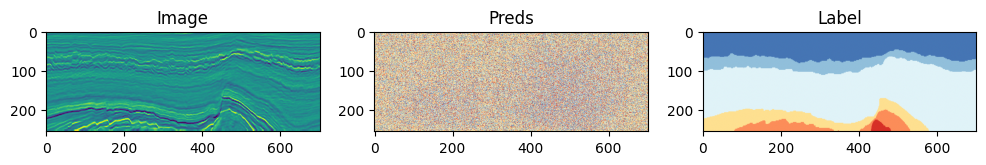

Batch 1: Loss=326514.8750


<Figure size 640x480 with 0 Axes>

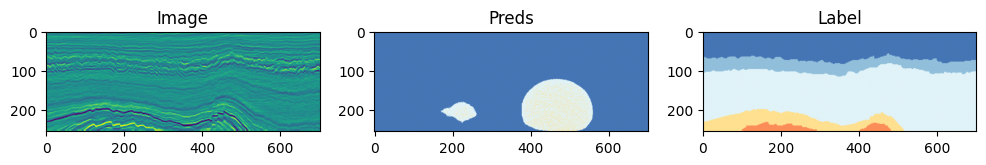

Batch 2: Loss=305164.4375


<Figure size 640x480 with 0 Axes>

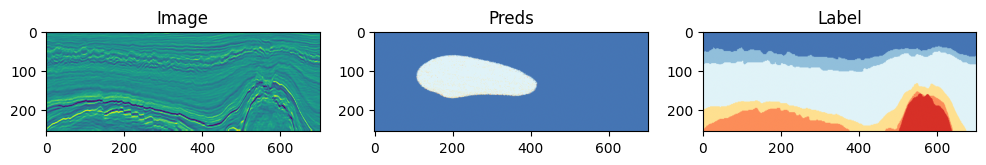

Batch 3: Loss=301200.1250


Metrics:
overall_accuracy: tensor(0.2634, device='cuda:0')
mean_class_accuracy: tensor(0.1666, device='cuda:0')
class_accuracy: tensor([0.6904, 0.0661, 0.1087, 0.1131, 0.0171, 0.0044], device='cuda:0')
mean_iou: tensor(0.0642, device='cuda:0')


In [140]:
metrics = {
    'overall_accuracy': Accuracy(task='multiclass', average='micro', num_classes=6),
    'mean_class_accuracy': Accuracy(task='multiclass', average='macro', num_classes=6),
    'class_accuracy': Accuracy(task='multiclass', average=None, num_classes=6),
    'mean_iou': MeanIoU(num_classes=6, input_format='index'),
}

for metric in metrics.values(): 
    metric.to(device)

for batch, (images, labels) in enumerate(train_dataloader):
    training_loss = run_batch(
        images, labels, criterion, optimizer, network, device=device, metrics=metrics, visualize=True, train=True
    )

    print(f'Batch {batch+1}: Loss={training_loss:.4f}')
    
    if batch == 2:
        break

print('\n\nMetrics:')
for key, value in metrics.items():
    print(key, value.compute(), sep=': ')

## Exercício 3

Dado que você tem o treinamento em uma única época na célula acima, implemente uma função que realize o treinamento e a validação, de acordo com os parâmetros abaixo:

-   `train_dataloader`: gerenciador de dados do subconjunto de treinamento
-   `valid_dataloader`: gerenciador de dados do subconjunto de validação
-   `criterion`: função de custo
-   `optimizer`: otimizador
-   `network`: modelo contendo a arquitetura escolhida
-   `device`: dispositivo onde o modelo será treinado (cpu ou cuda)
-   `num_epochs`: número de épocas durante o treinamento
-   `visual`: parâmetro boleano indicando exibição dos gráficos


In [141]:
# @title Definindo Treino e Validação
def train_valid_stage(
    train_dataloader,
    valid_dataloader,
    criterion,
    optimizer,
    network,
    device='cpu',
    num_epochs=10,
    visual=False,
):
    train_metrics = {
        'overall_accuracy': Accuracy(task='multiclass', average='micro', num_classes=6),
        'mean_class_accuracy': Accuracy(
            task='multiclass', average='macro', num_classes=6
        ),
        'class_accuracy': Accuracy(task='multiclass', average=None, num_classes=6),
        'mean_iou': MeanIoU(num_classes=6, input_format='index'),
    }
    valid_metrics = {
        'overall_accuracy': Accuracy(task='multiclass', average='micro', num_classes=6),
        'mean_class_accuracy': Accuracy(
            task='multiclass', average='macro', num_classes=6
        ),
        'class_accuracy': Accuracy(task='multiclass', average=None, num_classes=6),
        'mean_iou': MeanIoU(num_classes=6, input_format='index'),
    }
    train_metrics = {key: value.to(device) for key, value in train_metrics.items()}
    valid_metrics = {key: value.to(device) for key, value in valid_metrics.items()}

    for epoch in range(num_epochs):
        print(f'===== Epoch {epoch + 1} =====')
        # training step
        network.train()
        training_loss = 0.0
        train_dataloader.sampler.counter = 0

        for batch, (images, labels) in (pbar := tqdm(
            enumerate(train_dataloader), total=len(train_dataloader), unit='batches'
        )):
            training_loss += run_batch(
                images,
                labels,
                criterion,
                optimizer,
                network,
                device=device,
                metrics=train_metrics,
                train=True,
                visualize=(batch == 0) and visual,
            )

            pbar.set_description(f'Epoch {epoch + 1} | Loss: {training_loss / (batch + 1):.4f}')

        training_loss /= (batch + 1)

        # validation step
        network.eval()
        validation_loss = 0.0
        for batch, (images, labels) in enumerate(valid_dataloader):
            validation_loss += run_batch(
                images,
                labels,
                criterion,
                optimizer,
                network,
                device=device,
                metrics=valid_metrics,
                train=False,
                visualize=(batch == 0) and visual,
            )

        print('\n\nTraining Metrics:')
        print(f'Loss: {training_loss:.4f}')
        for key, value in train_metrics.items():
            print(key, value.compute(), sep=': ')
            value.reset()
        
        print('\nValidation Metrics:')
        print(f'Loss: {validation_loss:.4f}')
        for key, value in valid_metrics.items():
            print(key, value.compute(), sep=': ')
            value.reset()

===== Epoch 1 =====


  0%|          | 0/80 [00:00<?, ?batches/s]

<Figure size 640x480 with 0 Axes>

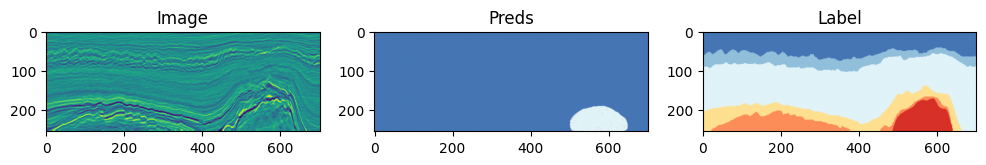

<Figure size 640x480 with 0 Axes>

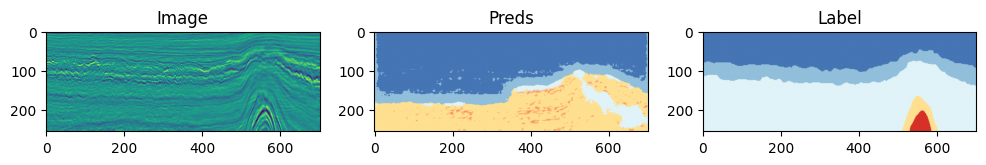



Training Metrics:
Loss: 158045.4746
overall_accuracy: tensor(0.6790, device='cuda:0')
mean_class_accuracy: tensor(0.3579, device='cuda:0')
class_accuracy: tensor([9.3748e-01, 2.1668e-01, 8.1226e-01, 1.7480e-01, 5.8996e-03, 3.3865e-04],
       device='cuda:0')
mean_iou: tensor(0.2667, device='cuda:0')

Validation Metrics:
Loss: 3909977.5625
overall_accuracy: tensor(0.5584, device='cuda:0')
mean_class_accuracy: tensor(0.4444, device='cuda:0')
class_accuracy: tensor([0.9860, 0.3818, 0.3302, 0.9686, 0.0000, 0.0000], device='cuda:0')
mean_iou: tensor(0.2355, device='cuda:0')
===== Epoch 2 =====


  0%|          | 0/80 [00:00<?, ?batches/s]

<Figure size 640x480 with 0 Axes>

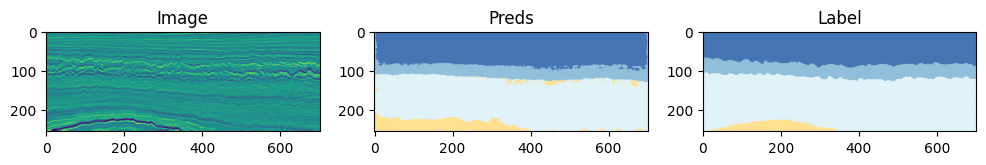

<Figure size 640x480 with 0 Axes>

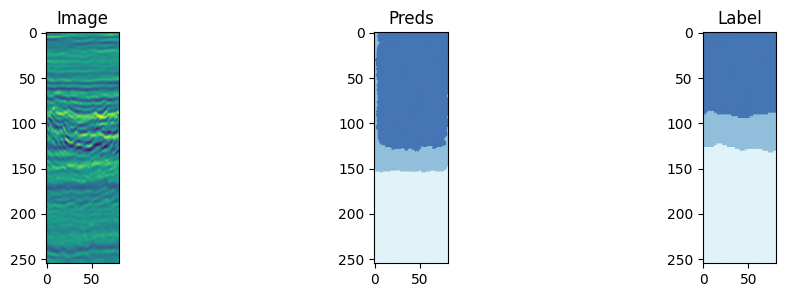



Training Metrics:
Loss: 78729.0660
overall_accuracy: tensor(0.8396, device='cuda:0')
mean_class_accuracy: tensor(0.5911, device='cuda:0')
class_accuracy: tensor([0.9341, 0.7155, 0.9312, 0.6216, 0.2617, 0.0828], device='cuda:0')
mean_iou: tensor(0.4784, device='cuda:0')

Validation Metrics:
Loss: 1787964.6299
overall_accuracy: tensor(0.8299, device='cuda:0')
mean_class_accuracy: tensor(0.3988, device='cuda:0')
class_accuracy: tensor([0.9684, 0.4605, 0.8609, 0.1031, 0.0000, 0.0000], device='cuda:0')
mean_iou: tensor(0.3308, device='cuda:0')
===== Epoch 3 =====


  0%|          | 0/80 [00:00<?, ?batches/s]

<Figure size 640x480 with 0 Axes>

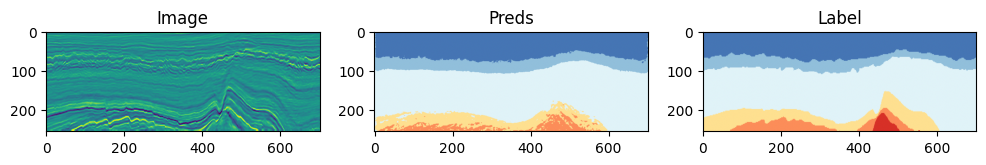

<Figure size 640x480 with 0 Axes>

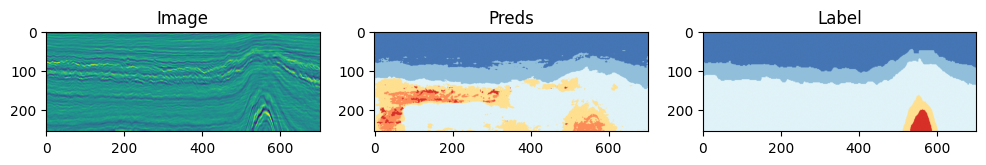



Training Metrics:
Loss: 46667.5820
overall_accuracy: tensor(0.8969, device='cuda:0')
mean_class_accuracy: tensor(0.7210, device='cuda:0')
class_accuracy: tensor([0.9635, 0.8693, 0.9482, 0.7018, 0.6222, 0.2211], device='cuda:0')
mean_iou: tensor(0.5844, device='cuda:0')

Validation Metrics:
Loss: 1289249.5625
overall_accuracy: tensor(0.8860, device='cuda:0')
mean_class_accuracy: tensor(0.5749, device='cuda:0')
class_accuracy: tensor([9.6774e-01, 9.3518e-01, 8.2933e-01, 7.1653e-01, 0.0000e+00, 6.4621e-04],
       device='cuda:0')
mean_iou: tensor(0.4423, device='cuda:0')
===== Epoch 4 =====


  0%|          | 0/80 [00:00<?, ?batches/s]

<Figure size 640x480 with 0 Axes>

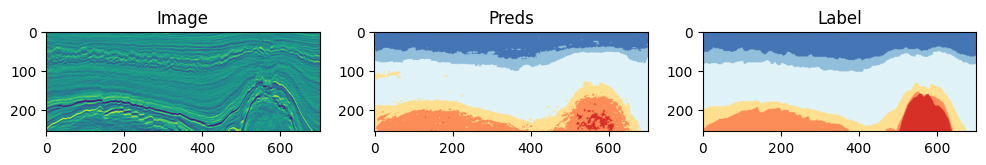

<Figure size 640x480 with 0 Axes>

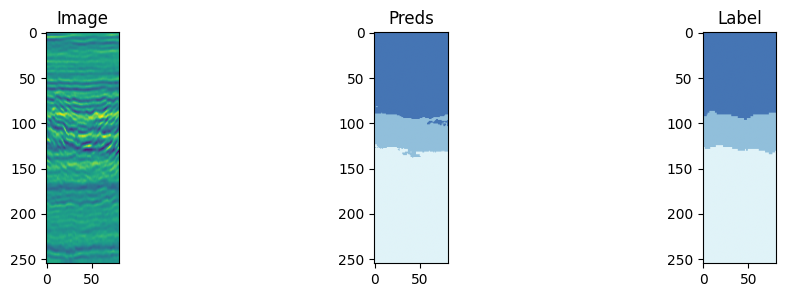



Training Metrics:
Loss: 29256.9858
overall_accuracy: tensor(0.9376, device='cuda:0')
mean_class_accuracy: tensor(0.8133, device='cuda:0')
class_accuracy: tensor([0.9785, 0.9083, 0.9740, 0.8589, 0.6898, 0.4701], device='cuda:0')
mean_iou: tensor(0.6692, device='cuda:0')

Validation Metrics:
Loss: 481950.3560
overall_accuracy: tensor(0.9589, device='cuda:0')
mean_class_accuracy: tensor(0.5609, device='cuda:0')
class_accuracy: tensor([0.9860, 0.8948, 0.9732, 0.5115, 0.0000, 0.0000], device='cuda:0')
mean_iou: tensor(0.4795, device='cuda:0')
===== Epoch 5 =====


  0%|          | 0/80 [00:00<?, ?batches/s]

<Figure size 640x480 with 0 Axes>

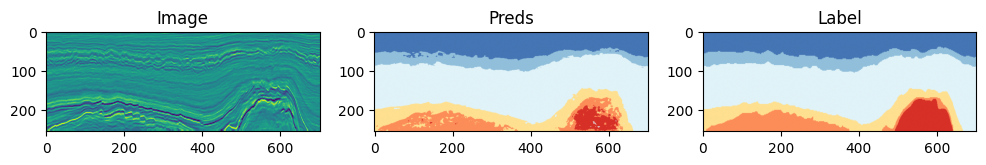

<Figure size 640x480 with 0 Axes>

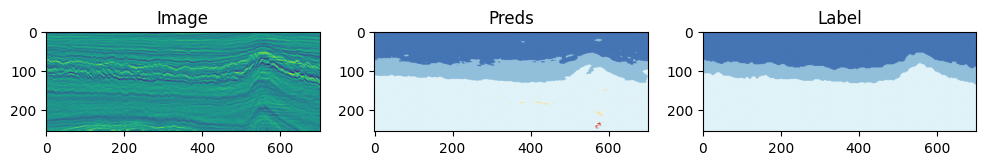



Training Metrics:
Loss: 22120.1541
overall_accuracy: tensor(0.9528, device='cuda:0')
mean_class_accuracy: tensor(0.8546, device='cuda:0')
class_accuracy: tensor([0.9853, 0.9196, 0.9821, 0.8965, 0.7706, 0.5737], device='cuda:0')
mean_iou: tensor(0.7095, device='cuda:0')

Validation Metrics:
Loss: 799939.0039
overall_accuracy: tensor(0.9390, device='cuda:0')
mean_class_accuracy: tensor(0.6592, device='cuda:0')
class_accuracy: tensor([0.8927, 0.9517, 0.9790, 0.2398, 0.0000, 0.8918], device='cuda:0')
mean_iou: tensor(0.4892, device='cuda:0')
===== Epoch 6 =====


  0%|          | 0/80 [00:00<?, ?batches/s]

<Figure size 640x480 with 0 Axes>

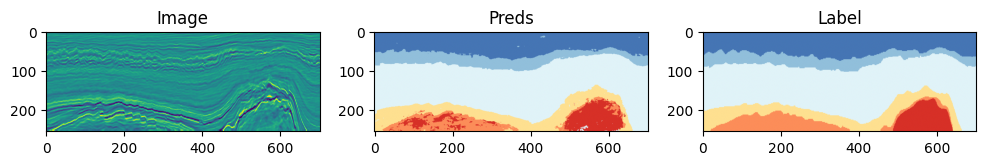

<Figure size 640x480 with 0 Axes>

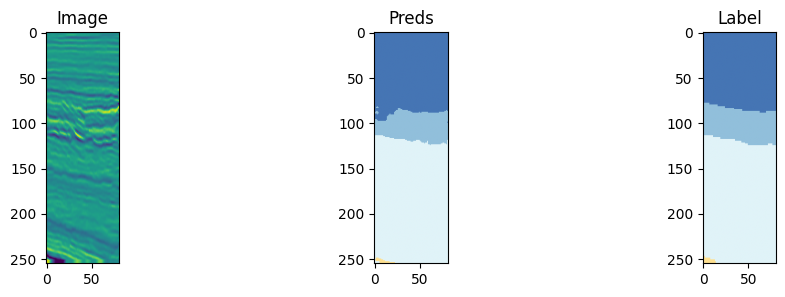



Training Metrics:
Loss: 21507.6190
overall_accuracy: tensor(0.9577, device='cuda:0')
mean_class_accuracy: tensor(0.8735, device='cuda:0')
class_accuracy: tensor([0.9867, 0.9177, 0.9836, 0.9170, 0.7975, 0.6385], device='cuda:0')
mean_iou: tensor(0.7262, device='cuda:0')

Validation Metrics:
Loss: 621758.8981
overall_accuracy: tensor(0.9519, device='cuda:0')
mean_class_accuracy: tensor(0.6623, device='cuda:0')
class_accuracy: tensor([0.9640, 0.8643, 0.9821, 0.5013, 0.0000, 0.0000], device='cuda:0')
mean_iou: tensor(0.4728, device='cuda:0')
===== Epoch 7 =====


  0%|          | 0/80 [00:00<?, ?batches/s]

<Figure size 640x480 with 0 Axes>

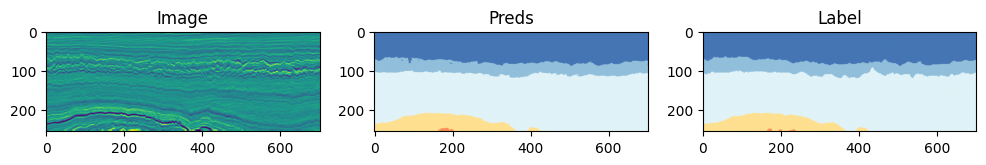

<Figure size 640x480 with 0 Axes>

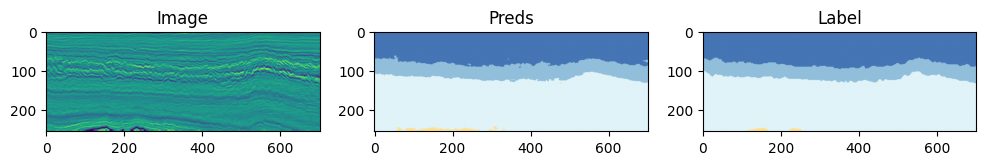



Training Metrics:
Loss: 17713.8140
overall_accuracy: tensor(0.9635, device='cuda:0')
mean_class_accuracy: tensor(0.9022, device='cuda:0')
class_accuracy: tensor([0.9853, 0.9290, 0.9862, 0.9207, 0.8214, 0.7706], device='cuda:0')
mean_iou: tensor(0.7455, device='cuda:0')

Validation Metrics:
Loss: 613848.4238
overall_accuracy: tensor(0.9449, device='cuda:0')
mean_class_accuracy: tensor(0.5828, device='cuda:0')
class_accuracy: tensor([0.9544, 0.9235, 0.9581, 0.4800, 0.0000, 0.1808], device='cuda:0')
mean_iou: tensor(0.4951, device='cuda:0')
===== Epoch 8 =====


  0%|          | 0/80 [00:00<?, ?batches/s]

<Figure size 640x480 with 0 Axes>

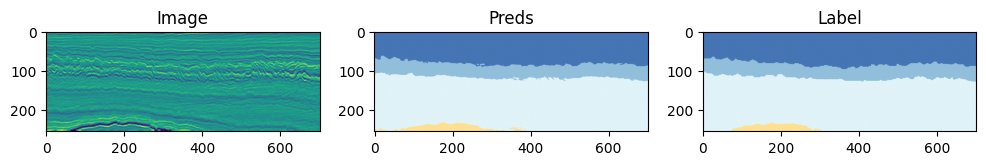

<Figure size 640x480 with 0 Axes>

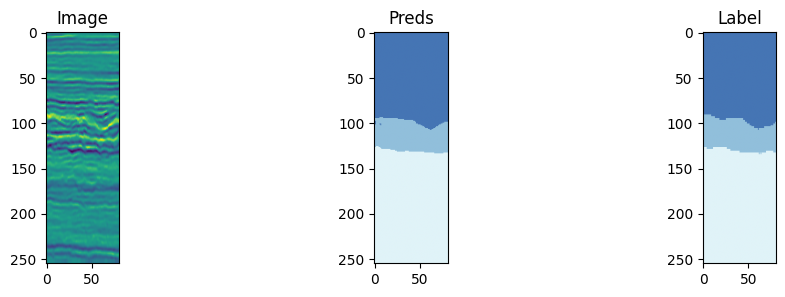



Training Metrics:
Loss: 13365.5528
overall_accuracy: tensor(0.9720, device='cuda:0')
mean_class_accuracy: tensor(0.9370, device='cuda:0')
class_accuracy: tensor([0.9891, 0.9374, 0.9875, 0.9377, 0.8781, 0.8924], device='cuda:0')
mean_iou: tensor(0.7746, device='cuda:0')

Validation Metrics:
Loss: 673162.1495
overall_accuracy: tensor(0.9481, device='cuda:0')
mean_class_accuracy: tensor(0.5664, device='cuda:0')
class_accuracy: tensor([0.9832, 0.8577, 0.9640, 0.5005, 0.0000, 0.0933], device='cuda:0')
mean_iou: tensor(0.4738, device='cuda:0')
===== Epoch 9 =====


  0%|          | 0/80 [00:00<?, ?batches/s]

<Figure size 640x480 with 0 Axes>

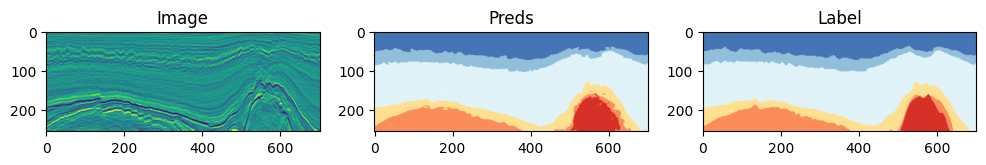

<Figure size 640x480 with 0 Axes>

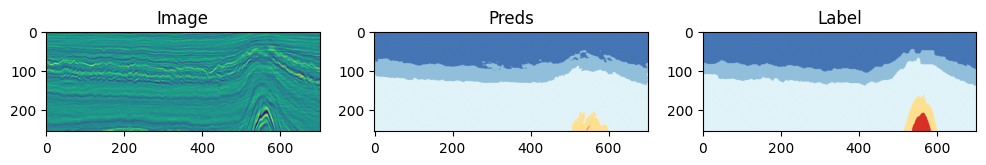



Training Metrics:
Loss: 23910.1509
overall_accuracy: tensor(0.9528, device='cuda:0')
mean_class_accuracy: tensor(0.8887, device='cuda:0')
class_accuracy: tensor([0.9794, 0.9099, 0.9785, 0.8856, 0.8142, 0.7648], device='cuda:0')
mean_iou: tensor(0.7306, device='cuda:0')

Validation Metrics:
Loss: 513101.1250
overall_accuracy: tensor(0.9622, device='cuda:0')
mean_class_accuracy: tensor(0.5732, device='cuda:0')
class_accuracy: tensor([0.9739, 0.9435, 0.9751, 0.4364, 0.0000, 0.1104], device='cuda:0')
mean_iou: tensor(0.5286, device='cuda:0')
===== Epoch 10 =====


  0%|          | 0/80 [00:00<?, ?batches/s]

<Figure size 640x480 with 0 Axes>

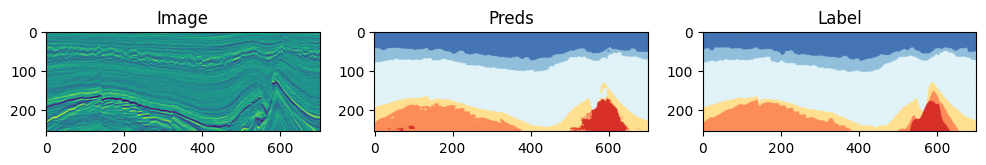

<Figure size 640x480 with 0 Axes>

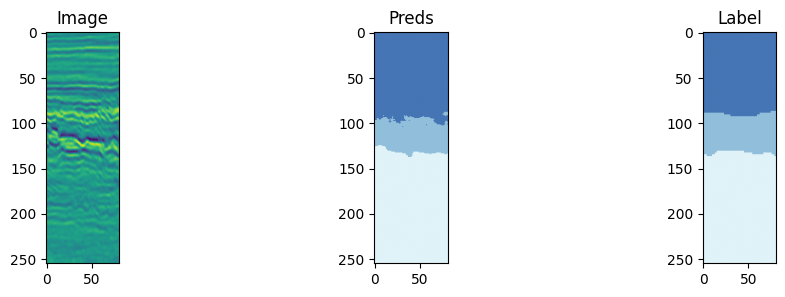



Training Metrics:
Loss: 12964.8091
overall_accuracy: tensor(0.9730, device='cuda:0')
mean_class_accuracy: tensor(0.9411, device='cuda:0')
class_accuracy: tensor([0.9895, 0.9379, 0.9879, 0.9387, 0.8861, 0.9062], device='cuda:0')
mean_iou: tensor(0.7780, device='cuda:0')

Validation Metrics:
Loss: 580823.6652
overall_accuracy: tensor(0.9560, device='cuda:0')
mean_class_accuracy: tensor(0.5436, device='cuda:0')
class_accuracy: tensor([0.9889, 0.8602, 0.9772, 0.4073, 0.0000, 0.0279], device='cuda:0')
mean_iou: tensor(0.4774, device='cuda:0')
===== Epoch 11 =====


  0%|          | 0/80 [00:00<?, ?batches/s]

<Figure size 640x480 with 0 Axes>

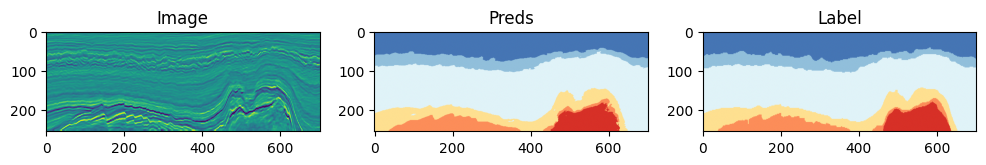

<Figure size 640x480 with 0 Axes>

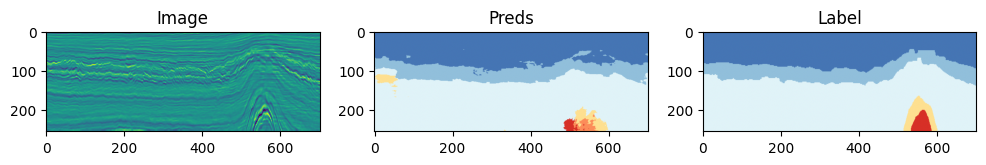



Training Metrics:
Loss: 11084.2246
overall_accuracy: tensor(0.9768, device='cuda:0')
mean_class_accuracy: tensor(0.9506, device='cuda:0')
class_accuracy: tensor([0.9914, 0.9434, 0.9888, 0.9519, 0.9098, 0.9182], device='cuda:0')
mean_iou: tensor(0.7931, device='cuda:0')

Validation Metrics:
Loss: 574240.9766
overall_accuracy: tensor(0.9572, device='cuda:0')
mean_class_accuracy: tensor(0.5833, device='cuda:0')
class_accuracy: tensor([0.9707, 0.9216, 0.9722, 0.4809, 0.0000, 0.1541], device='cuda:0')
mean_iou: tensor(0.5320, device='cuda:0')
===== Epoch 12 =====


  0%|          | 0/80 [00:00<?, ?batches/s]

<Figure size 640x480 with 0 Axes>

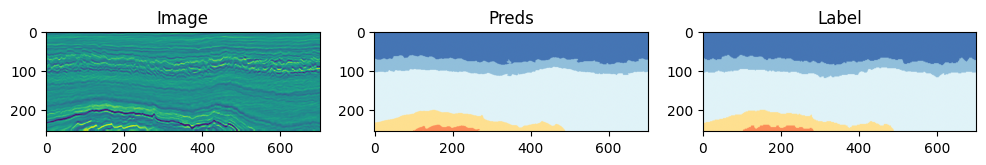

KeyboardInterrupt: 

In [142]:
train_valid_stage(
    train_dataloader,
    valid_dataloader,
    criterion,
    optimizer,
    network,
    device=device,
    num_epochs=12,
    visual=True,
)

## Data Augmentation

Data augmentation é uma técnica usada para aumentar a quantidade e diversidade de dados de treinamento em aprendizado de máquina, principalmente no caso de imagens. Imagine que você tem um número limitado de imagens para treinar seu modelo de reconhecimento facial. Através da data augmentation, você cria variações artificiais dessas imagens originais para "enganar" o modelo e torná-lo mais robusto.

Veja como funciona:

-   Aplicando transformações geométricas: Você pode rotacionar, escalar, recortar e aplicar espelhamento nas imagens originais. Por exemplo, rotacionar uma imagem de rosto ligeiramente para a esquerda ou direita cria uma nova imagem que o modelo nunca viu antes, mas que ainda representa um rosto.
-   Ajustando o brilho e contraste: Aumentando ou diminuindo o brilho e contraste das imagens, simula diferentes condições de iluminação nas quais o modelo pode precisar funcionar.
-   Simulando oclusões: Introduzindo pequenas obstruções aleatórias nas imagens, como óculos escuros ou cabelo na frente do rosto, o modelo aprende a lidar com situações do mundo real onde a visão pode ser parcialmente bloqueada.

Veja alguns benefícios do data augmentation:

-   Evita overfitting: Quando um modelo treina somente em dados muito específicos, ele pode se tornar muito bom em identificar aqueles dados, mas ter um péssimo desempenho em dados ligeiramente diferentes. A data augmentation ajuda a prevenir isso, expondo o modelo a uma maior variedade de cenários.
-   Melhora a generalização: O objetivo final é que o modelo funcione bem em dados novos e nunca vistos antes. A data augmentation ajuda o modelo a aprender características gerais que se aplicam a um tipo de dado, em vez de memorizar detalhes específicos dos dados de treinamento.
-   Reduz a necessidade de coleta de dados: Coletar grandes quantidades de dados rotulados pode ser caro e demorado. A data augmentation permite que você aproveite ao máximo os dados que já possui.


## Exercício 4

Retreine sua rede utilizando _data augmentation_ e o otimizador `torch.optim.Adam`.

Houve alguma mudança nos resultados? E no tempo de convergência da rede?


In [144]:
data_aug = T.Compose([T.RandomRotation(degrees=10), T.RandomVerticalFlip()])

input_transforms = T.Compose([
    T.Normalize((train_inputs.mean(), ), (train_inputs.std(), ))
])


# TODO: Defina os datasets de treino e validação baseados nos subsets obtidos
train_dataset = F3BlockDataset(train_inputs, train_labels, input_transforms, data_aug)
valid_dataset = F3BlockDataset(valid_inputs, valid_labels, input_transforms, data_aug)

train_dataloader = DataLoader(
    train_dataset,
    batch_size=4,
    sampler=CustomSampler(train_dataset.sections),
    num_workers=0
)
valid_dataloader = DataLoader(
    valid_dataset, batch_size=4, sampler=CustomSampler(valid_dataset.sections), num_workers=0
)

===== Epoch 1 =====


  0%|          | 0/80 [00:00<?, ?batches/s]

<Figure size 640x480 with 0 Axes>

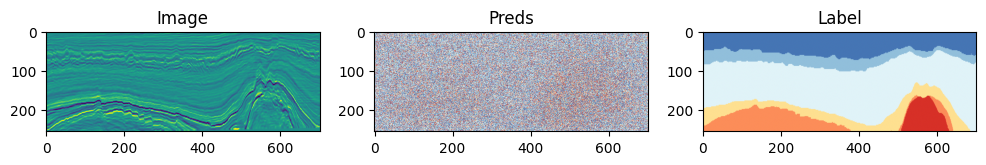

<Figure size 640x480 with 0 Axes>

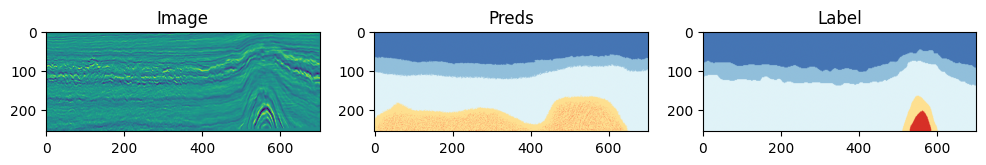



Training Metrics:
Loss: 146301.4714
overall_accuracy: tensor(0.7477, device='cuda:0')
mean_class_accuracy: tensor(0.4794, device='cuda:0')
class_accuracy: tensor([0.9188, 0.5861, 0.8224, 0.4868, 0.0366, 0.0260], device='cuda:0')
mean_iou: tensor(0.3785, device='cuda:0')

Validation Metrics:
Loss: 2296490.8906
overall_accuracy: tensor(0.7985, device='cuda:0')
mean_class_accuracy: tensor(0.5296, device='cuda:0')
class_accuracy: tensor([9.1676e-01, 7.2492e-01, 7.4804e-01, 7.8747e-01, 0.0000e+00, 1.9147e-04],
       device='cuda:0')
mean_iou: tensor(0.3752, device='cuda:0')
===== Epoch 2 =====


  0%|          | 0/80 [00:00<?, ?batches/s]

<Figure size 640x480 with 0 Axes>

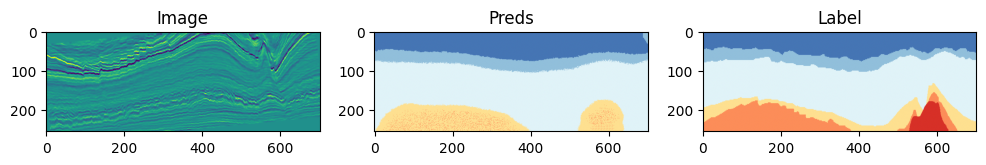

<Figure size 640x480 with 0 Axes>

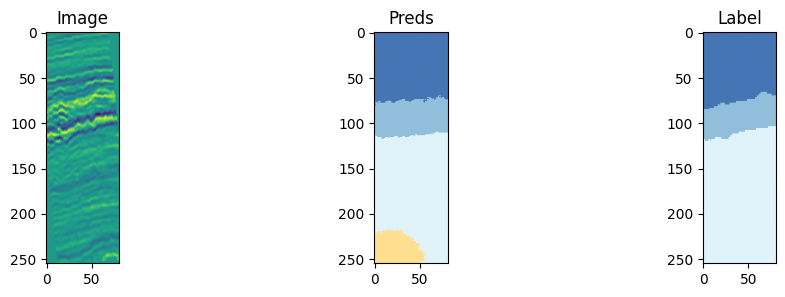



Training Metrics:
Loss: 79242.9209
overall_accuracy: tensor(0.8508, device='cuda:0')
mean_class_accuracy: tensor(0.6149, device='cuda:0')
class_accuracy: tensor([0.9570, 0.7836, 0.9182, 0.6012, 0.4222, 0.0073], device='cuda:0')
mean_iou: tensor(0.4958, device='cuda:0')

Validation Metrics:
Loss: 1577517.5220
overall_accuracy: tensor(0.8611, device='cuda:0')
mean_class_accuracy: tensor(0.4487, device='cuda:0')
class_accuracy: tensor([0.8908, 0.7129, 0.9004, 0.1878, 0.0000, 0.0000], device='cuda:0')
mean_iou: tensor(0.3789, device='cuda:0')
===== Epoch 3 =====


  0%|          | 0/80 [00:00<?, ?batches/s]

<Figure size 640x480 with 0 Axes>

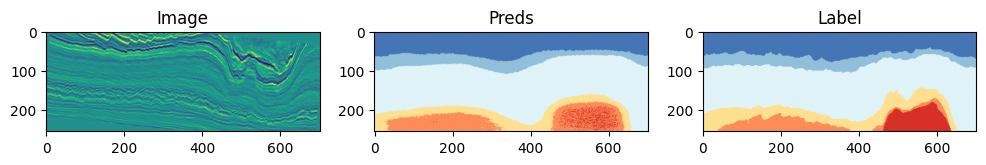

<Figure size 640x480 with 0 Axes>

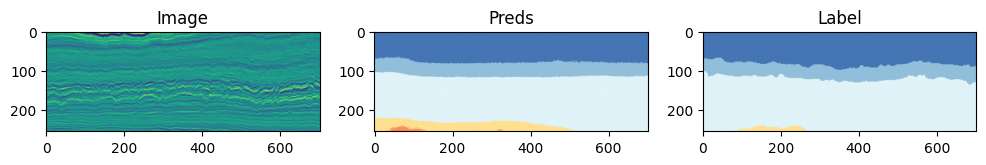



Training Metrics:
Loss: 70784.5573
overall_accuracy: tensor(0.8516, device='cuda:0')
mean_class_accuracy: tensor(0.6554, device='cuda:0')
class_accuracy: tensor([0.9543, 0.7500, 0.9184, 0.5682, 0.5186, 0.2227], device='cuda:0')
mean_iou: tensor(0.5124, device='cuda:0')

Validation Metrics:
Loss: 1909931.6562
overall_accuracy: tensor(0.7952, device='cuda:0')
mean_class_accuracy: tensor(0.4847, device='cuda:0')
class_accuracy: tensor([0.8808, 0.6816, 0.7829, 0.4078, 0.0000, 0.1549], device='cuda:0')
mean_iou: tensor(0.3667, device='cuda:0')
===== Epoch 4 =====


  0%|          | 0/80 [00:00<?, ?batches/s]

<Figure size 640x480 with 0 Axes>

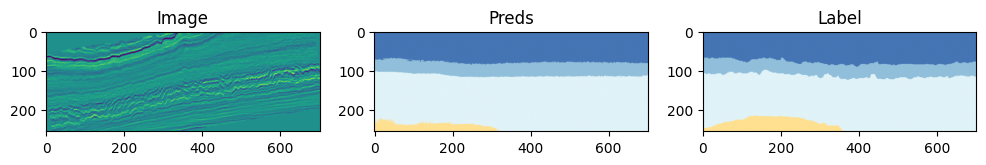

<Figure size 640x480 with 0 Axes>

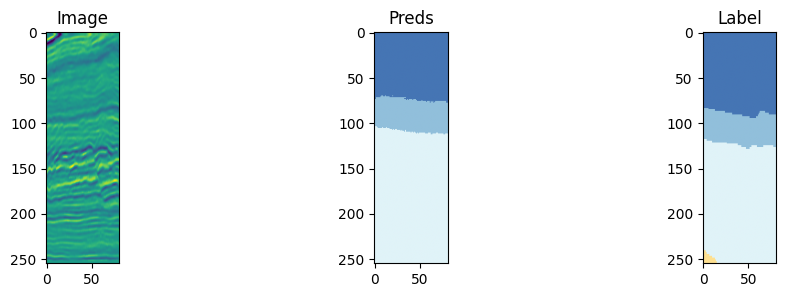



Training Metrics:
Loss: 55111.4708
overall_accuracy: tensor(0.8869, device='cuda:0')
mean_class_accuracy: tensor(0.7430, device='cuda:0')
class_accuracy: tensor([0.9651, 0.8134, 0.9406, 0.6489, 0.5955, 0.4944], device='cuda:0')
mean_iou: tensor(0.5752, device='cuda:0')

Validation Metrics:
Loss: 1695964.9893
overall_accuracy: tensor(0.8594, device='cuda:0')
mean_class_accuracy: tensor(0.4767, device='cuda:0')
class_accuracy: tensor([0.8344, 0.5607, 0.9773, 0.0111, 0.0000, 0.0000], device='cuda:0')
mean_iou: tensor(0.3497, device='cuda:0')
===== Epoch 5 =====


  0%|          | 0/80 [00:00<?, ?batches/s]

<Figure size 640x480 with 0 Axes>

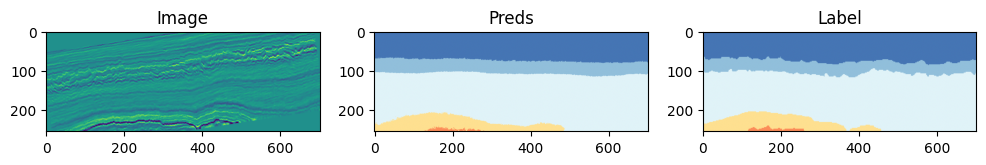

<Figure size 640x480 with 0 Axes>

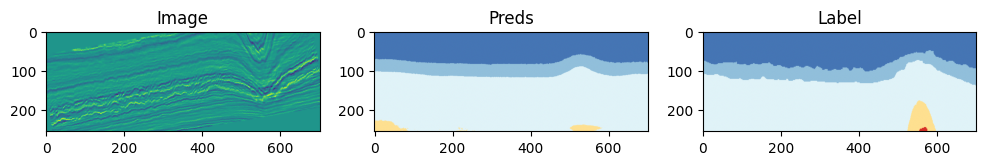



Training Metrics:
Loss: 49946.6099
overall_accuracy: tensor(0.8939, device='cuda:0')
mean_class_accuracy: tensor(0.7713, device='cuda:0')
class_accuracy: tensor([0.9659, 0.8150, 0.9453, 0.6604, 0.6258, 0.6152], device='cuda:0')
mean_iou: tensor(0.5939, device='cuda:0')

Validation Metrics:
Loss: 1012331.6484
overall_accuracy: tensor(0.9121, device='cuda:0')
mean_class_accuracy: tensor(0.5039, device='cuda:0')
class_accuracy: tensor([0.9320, 0.7214, 0.9675, 0.3129, 0.0000, 0.0896], device='cuda:0')
mean_iou: tensor(0.4283, device='cuda:0')
===== Epoch 6 =====


  0%|          | 0/80 [00:00<?, ?batches/s]

<Figure size 640x480 with 0 Axes>

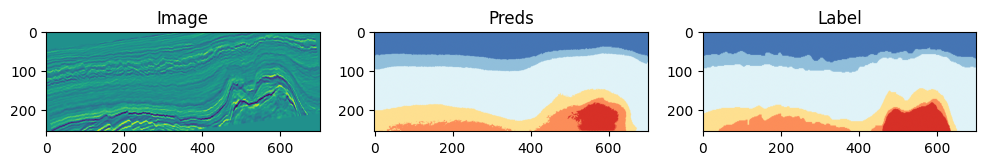

<Figure size 640x480 with 0 Axes>

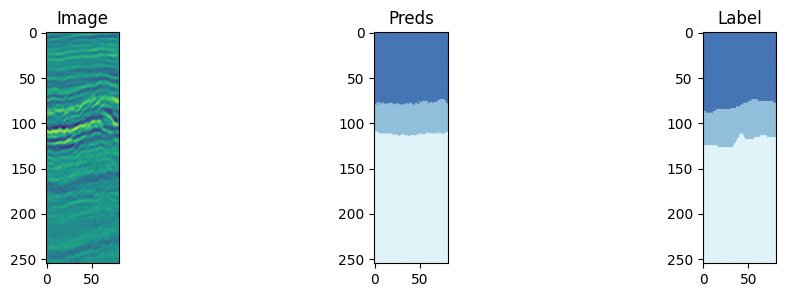



Training Metrics:
Loss: 43891.6316
overall_accuracy: tensor(0.9067, device='cuda:0')
mean_class_accuracy: tensor(0.8063, device='cuda:0')
class_accuracy: tensor([0.9702, 0.8439, 0.9489, 0.6883, 0.6990, 0.6878], device='cuda:0')
mean_iou: tensor(0.6205, device='cuda:0')

Validation Metrics:
Loss: 1331334.7852
overall_accuracy: tensor(0.8820, device='cuda:0')
mean_class_accuracy: tensor(0.4951, device='cuda:0')
class_accuracy: tensor([0.8819, 0.6140, 0.9767, 0.0032, 0.0000, 0.0000], device='cuda:0')
mean_iou: tensor(0.3700, device='cuda:0')
===== Epoch 7 =====


  0%|          | 0/80 [00:00<?, ?batches/s]

<Figure size 640x480 with 0 Axes>

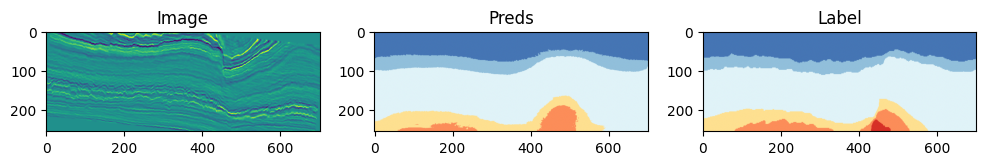

<Figure size 640x480 with 0 Axes>

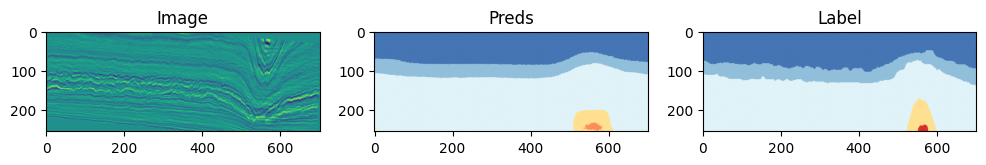



Training Metrics:
Loss: 41653.7143
overall_accuracy: tensor(0.9096, device='cuda:0')
mean_class_accuracy: tensor(0.8038, device='cuda:0')
class_accuracy: tensor([0.9715, 0.8459, 0.9528, 0.7046, 0.6945, 0.6537], device='cuda:0')
mean_iou: tensor(0.6245, device='cuda:0')

Validation Metrics:
Loss: 836345.5273
overall_accuracy: tensor(0.9243, device='cuda:0')
mean_class_accuracy: tensor(0.5369, device='cuda:0')
class_accuracy: tensor([0.9453, 0.7595, 0.9698, 0.4217, 0.0000, 0.1251], device='cuda:0')
mean_iou: tensor(0.4462, device='cuda:0')
===== Epoch 8 =====


  0%|          | 0/80 [00:00<?, ?batches/s]

<Figure size 640x480 with 0 Axes>

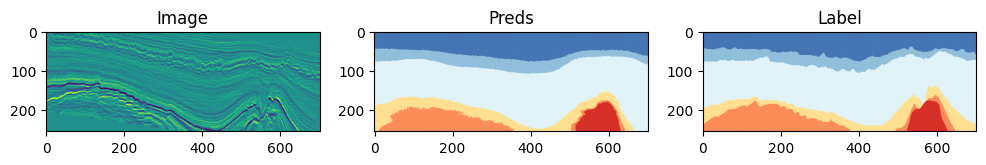

<Figure size 640x480 with 0 Axes>

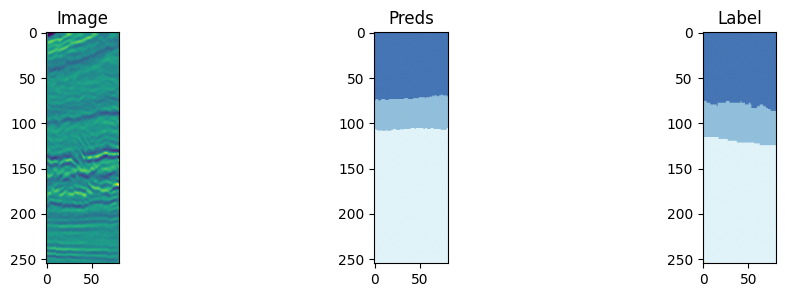



Training Metrics:
Loss: 36111.3835
overall_accuracy: tensor(0.9218, device='cuda:0')
mean_class_accuracy: tensor(0.8434, device='cuda:0')
class_accuracy: tensor([0.9740, 0.8616, 0.9579, 0.7430, 0.7365, 0.7877], device='cuda:0')
mean_iou: tensor(0.6542, device='cuda:0')

Validation Metrics:
Loss: 1678996.5078
overall_accuracy: tensor(0.8726, device='cuda:0')
mean_class_accuracy: tensor(0.4990, device='cuda:0')
class_accuracy: tensor([0.8667, 0.5898, 0.9734, 0.0650, 0.0000, 0.0000], device='cuda:0')
mean_iou: tensor(0.3710, device='cuda:0')
===== Epoch 9 =====


  0%|          | 0/80 [00:00<?, ?batches/s]

<Figure size 640x480 with 0 Axes>

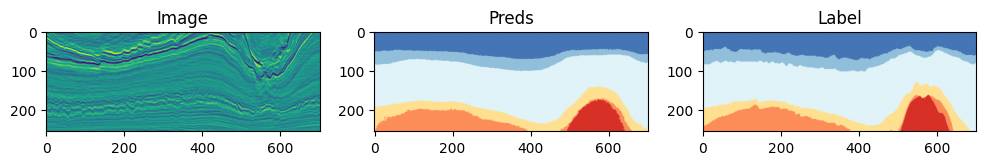

<Figure size 640x480 with 0 Axes>

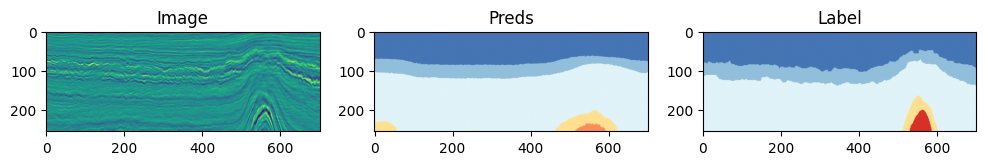



Training Metrics:
Loss: 31565.8338
overall_accuracy: tensor(0.9317, device='cuda:0')
mean_class_accuracy: tensor(0.8677, device='cuda:0')
class_accuracy: tensor([0.9749, 0.8718, 0.9632, 0.7929, 0.7599, 0.8432], device='cuda:0')
mean_iou: tensor(0.6783, device='cuda:0')

Validation Metrics:
Loss: 1027604.3594
overall_accuracy: tensor(0.9072, device='cuda:0')
mean_class_accuracy: tensor(0.5265, device='cuda:0')
class_accuracy: tensor([0.9348, 0.7175, 0.9529, 0.5537, 0.0000, 0.0000], device='cuda:0')
mean_iou: tensor(0.4293, device='cuda:0')
===== Epoch 10 =====


  0%|          | 0/80 [00:00<?, ?batches/s]

<Figure size 640x480 with 0 Axes>

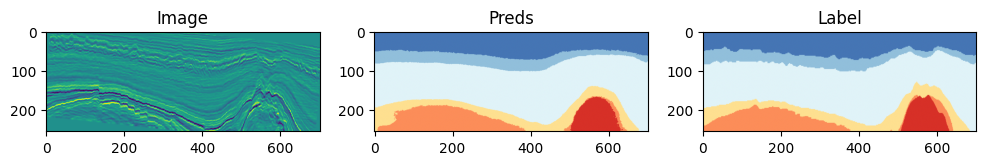

<Figure size 640x480 with 0 Axes>

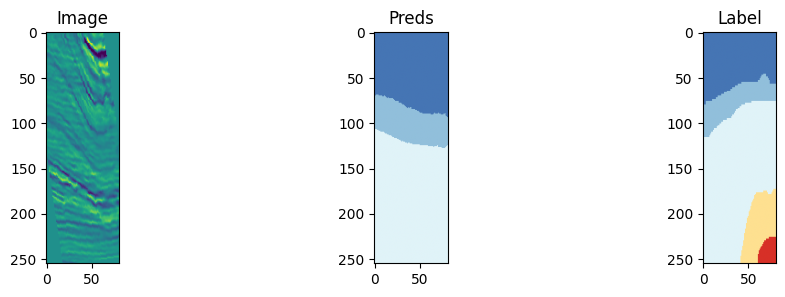



Training Metrics:
Loss: 31869.0964
overall_accuracy: tensor(0.9299, device='cuda:0')
mean_class_accuracy: tensor(0.8654, device='cuda:0')
class_accuracy: tensor([0.9739, 0.8643, 0.9623, 0.7878, 0.7656, 0.8383], device='cuda:0')
mean_iou: tensor(0.6742, device='cuda:0')

Validation Metrics:
Loss: 1651860.4727
overall_accuracy: tensor(0.8749, device='cuda:0')
mean_class_accuracy: tensor(0.4911, device='cuda:0')
class_accuracy: tensor([0.8806, 0.5766, 0.9736, 0.0246, 0.0000, 0.0000], device='cuda:0')
mean_iou: tensor(0.3651, device='cuda:0')
===== Epoch 11 =====


  0%|          | 0/80 [00:00<?, ?batches/s]

<Figure size 640x480 with 0 Axes>

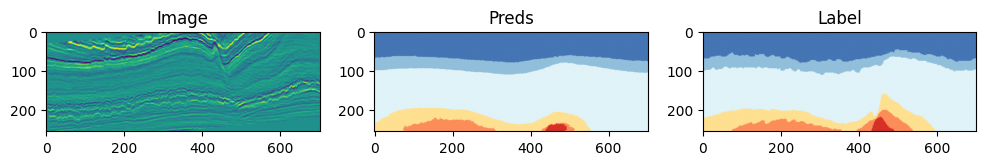

<Figure size 640x480 with 0 Axes>

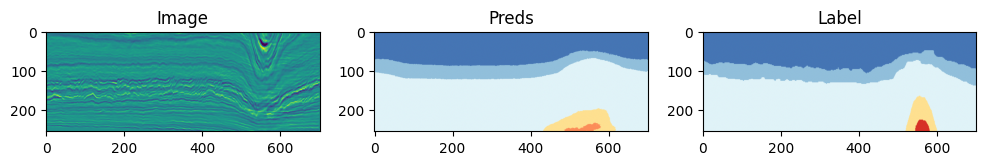



Training Metrics:
Loss: 27054.6480
overall_accuracy: tensor(0.9404, device='cuda:0')
mean_class_accuracy: tensor(0.8868, device='cuda:0')
class_accuracy: tensor([0.9782, 0.8869, 0.9676, 0.8189, 0.7888, 0.8806], device='cuda:0')
mean_iou: tensor(0.6978, device='cuda:0')

Validation Metrics:
Loss: 918110.6582
overall_accuracy: tensor(0.9211, device='cuda:0')
mean_class_accuracy: tensor(0.5365, device='cuda:0')
class_accuracy: tensor([0.9373, 0.7575, 0.9681, 0.4952, 0.0000, 0.0606], device='cuda:0')
mean_iou: tensor(0.4518, device='cuda:0')
===== Epoch 12 =====


  0%|          | 0/80 [00:00<?, ?batches/s]

<Figure size 640x480 with 0 Axes>

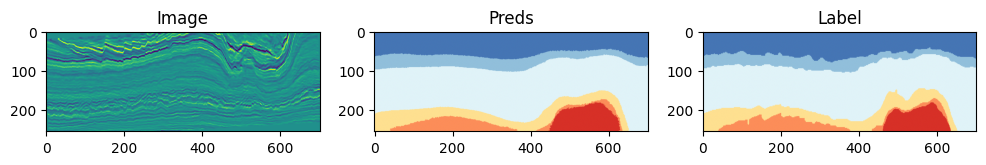

<Figure size 640x480 with 0 Axes>

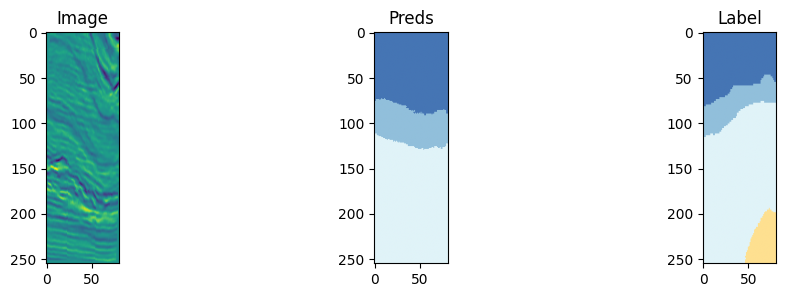



Training Metrics:
Loss: 23967.9922
overall_accuracy: tensor(0.9472, device='cuda:0')
mean_class_accuracy: tensor(0.9005, device='cuda:0')
class_accuracy: tensor([0.9797, 0.8942, 0.9716, 0.8480, 0.8151, 0.8946], device='cuda:0')
mean_iou: tensor(0.7136, device='cuda:0')

Validation Metrics:
Loss: 1520945.5159
overall_accuracy: tensor(0.8795, device='cuda:0')
mean_class_accuracy: tensor(0.4969, device='cuda:0')
class_accuracy: tensor([0.8756, 0.6381, 0.9693, 0.0013, 0.0000, 0.0000], device='cuda:0')
mean_iou: tensor(0.3690, device='cuda:0')


In [145]:
network = DeconvNet(n_channels=1, n_classes=train_dataset.n_classes).to(device)
criterion = nn.CrossEntropyLoss(reduction='sum', weight=None)
optimizer = torch.optim.Adam(network.parameters(), lr=3e-4, amsgrad=True)

torch.cuda.empty_cache()

train_valid_stage(
    train_dataloader,
    valid_dataloader,
    criterion,
    optimizer,
    network,
    device=device,
    num_epochs=12,
    visual=True,
)

## Desafio

Até agora, você implementou o treinamento e validação utilizando exclusivamente o bloco de treinamento. Está na hora de verificar a acurácia de seu método nos conjuntos de testes. Entretanto, desta vez, você poderá utilizar artifícios como data augmentation e, até mesmo, três canais na entrada de sua rede.

Implemente a predição em um dos conjuntos de teste da base de dados _F3 Block_ (_test1_ ou _test2_).
